In [1]:
from typing import Tuple, List, Optional, Dict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import lightgbm as lgb

import graphviz

from sklearn import linear_model
from sklearn import tree
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import StratifiedKFold

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder as OHE

from sksurv.datasets import get_x_y
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis, ComponentwiseGradientBoostingSurvivalAnalysis, ExtraSurvivalTrees
from sksurv.linear_model import CoxPHSurvivalAnalysis

from utils import *

# Enable higher resolution plots
%config InlineBackend.figure_format = 'retina'

# Autoreload modules
%reload_ext autoreload
%autoreload 2

In [2]:
pd.set_option('display.max_columns', None) # display all columns when plotting a dataframe

We create the custom made colormap for the SHAP value plots. 

Source: https://stackoverflow.com/questions/16834861/create-own-colormap-using-matplotlib-and-plot-color-scale

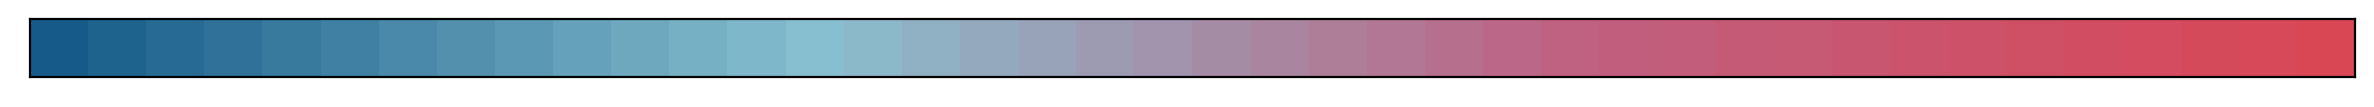

In [3]:
custom_cmap = make_custom_colormap( ['#165b89','#88c0d0','#bf6182','#d94755' ] )

## CatBoost 

### Calssifier

In [4]:
(catboost_clf_shap, 
catboost_clf_shap_0, catboost_clf_shap_1, catboost_clf_shap_2, catboost_clf_shap_3, catboost_clf_shap_4, 
catboost_clf_df, catboost_clf_summary_df) = shap_values_feature_importance('catboost_clf',5)  

In [5]:
catboost_clf_summary_df

,fold_1,fold_2,fold_3,fold_4,fold_5,sum
Features,,,,,,
STAND UP FROM CHAIR,1,1,1,1,1,5
RISE FROM FLOOR,1,1,1,1,1,5
6MWD_DISWLK,1,1,1,1,1,5
WALK,1,1,1,1,1,5
STAND,0,1,1,1,1,4
TEARING PAPER,1,1,0,1,1,4
4SCA_SHOES,1,1,1,1,0,4
4SCA_4-AGRAD,1,1,0,1,0,3
RISE_FROM_FLOOR,1,0,1,0,1,3


In [6]:
catboost_clf_shap_values, catboost_clf_x_test = concatenate('catboost_clf', 5)

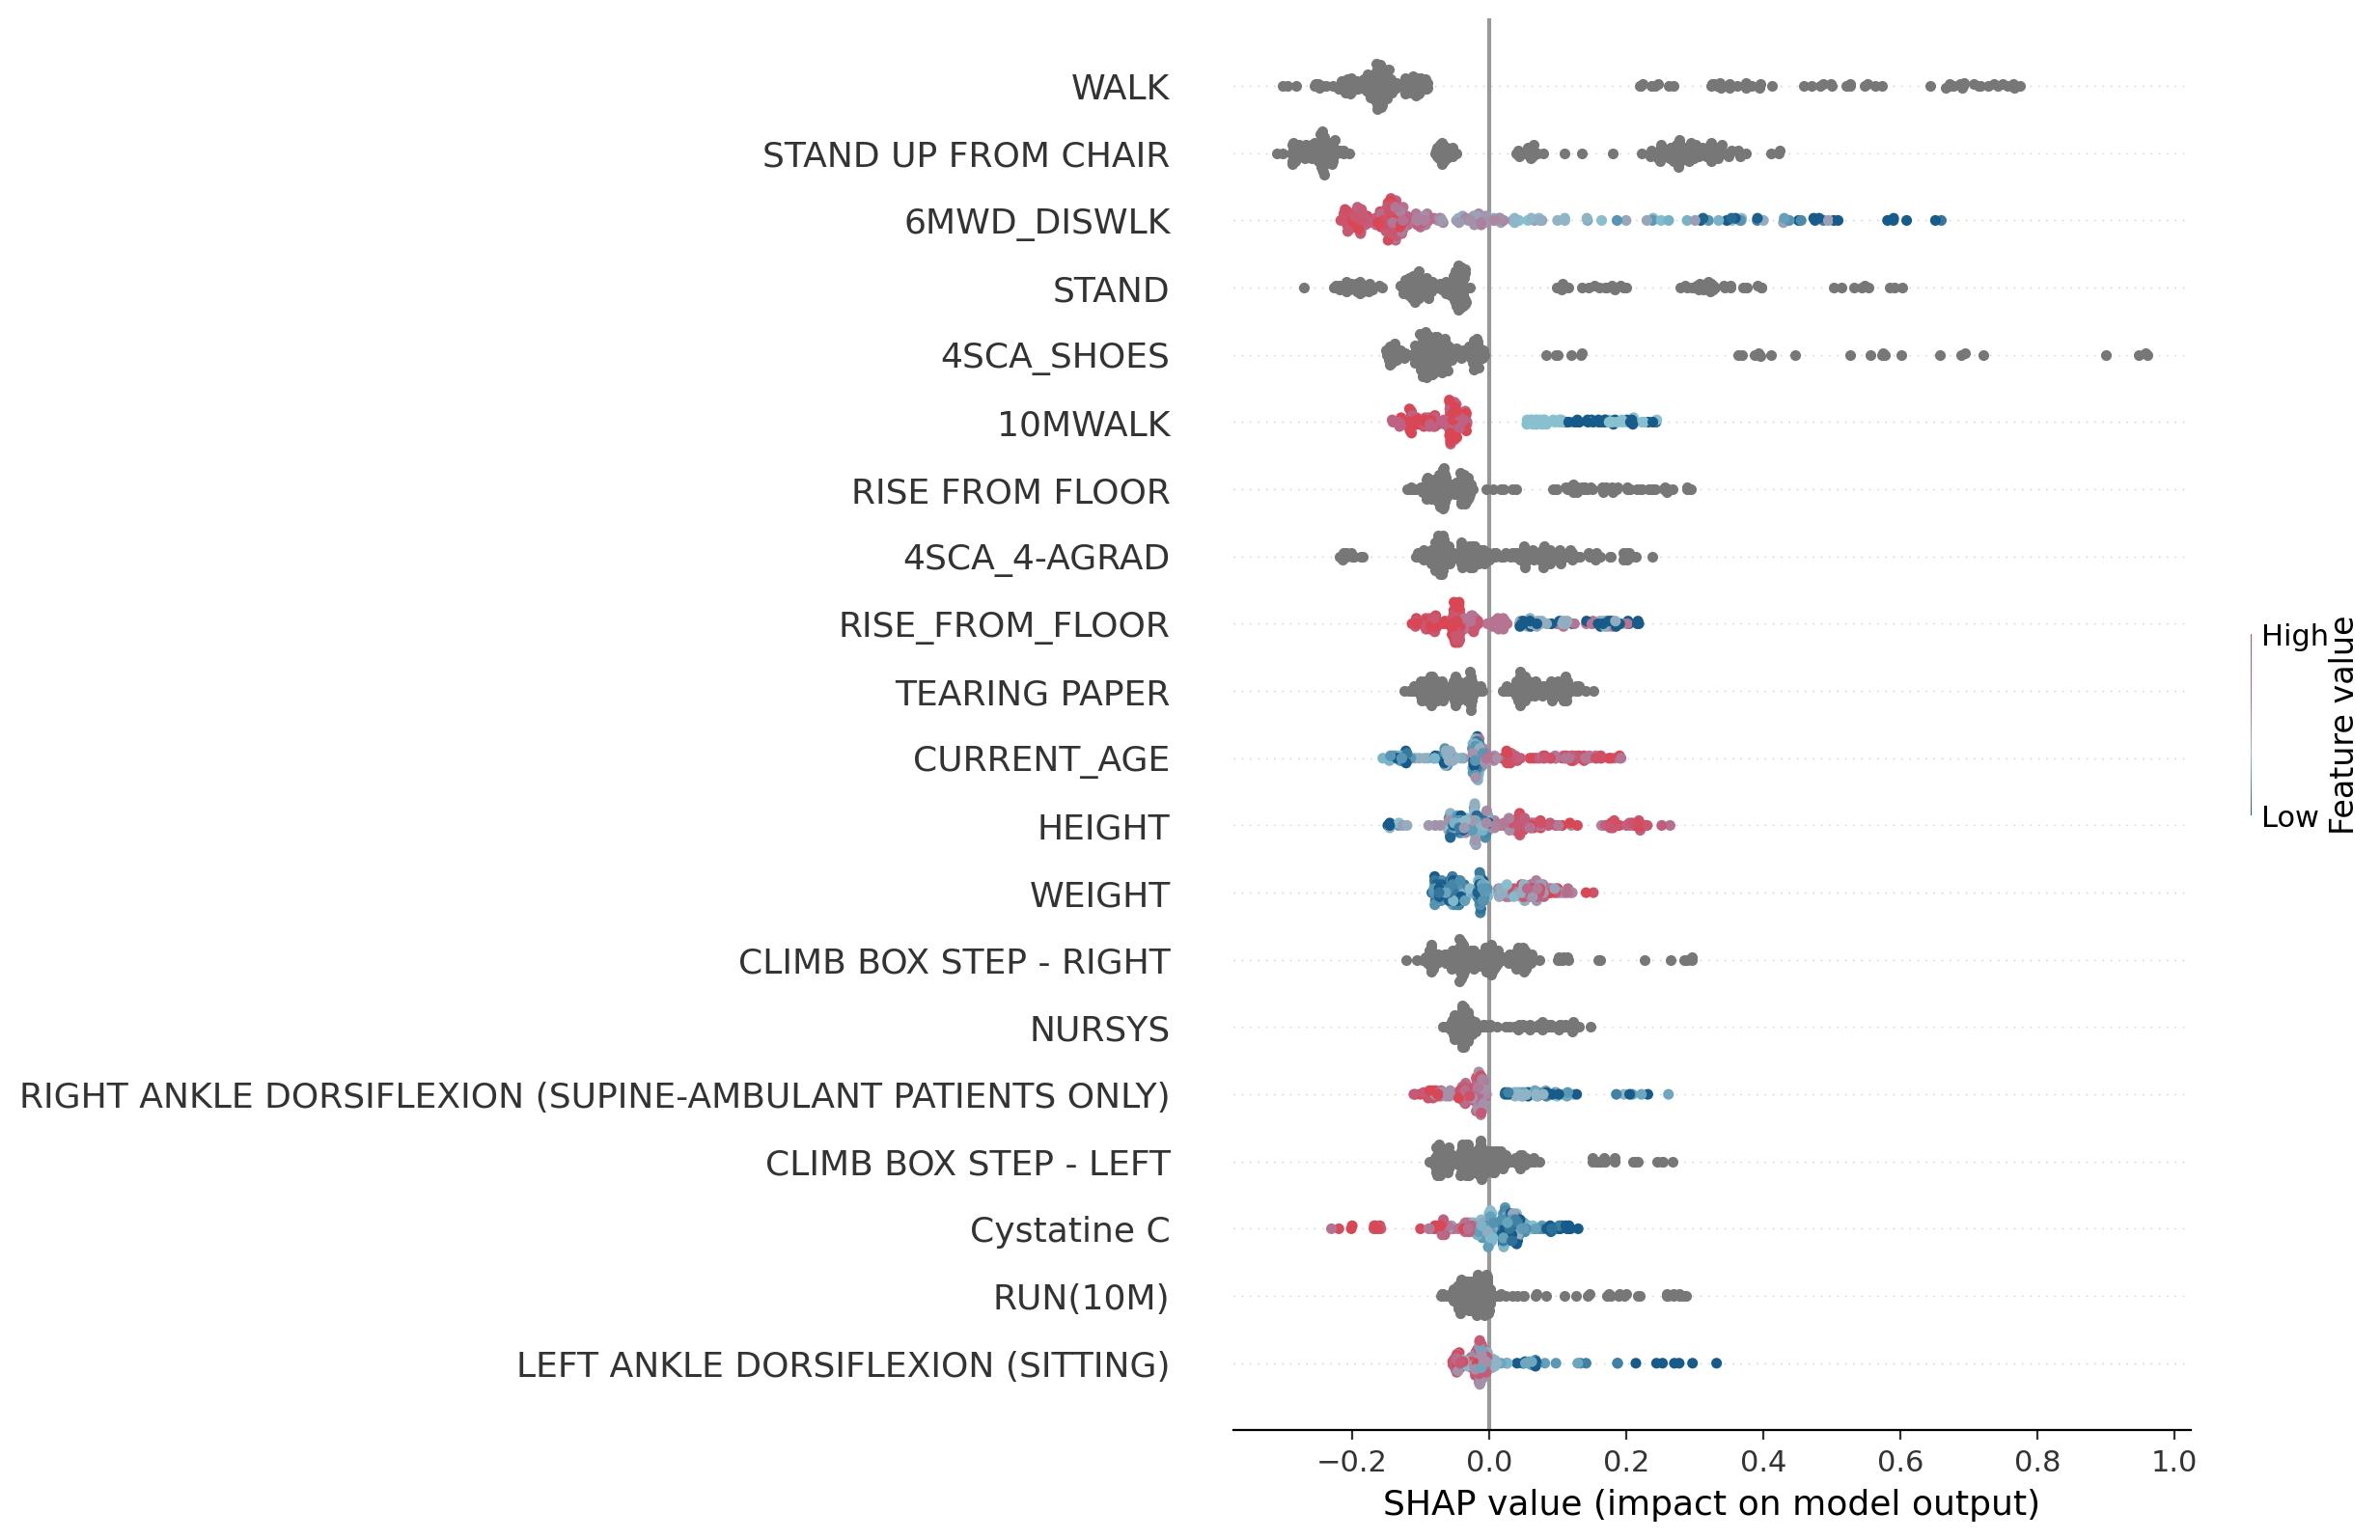

In [7]:
shap.summary_plot(catboost_clf_shap_values, catboost_clf_x_test, cmap=custom_cmap)

In [8]:
catboost_clf_x_test = catboost_clf_x_test.rename(columns={'WALK_2= WALKS WITH HEEL-TOE OR FLAT-FOOTED GAIT PATTERN':'WALK-2', 
                                        'STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS':'STAND-2', 
                                        'RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE': 'RISE FROM FLOOR-0', 
                                        'STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP': 'STAND UP FROM CHAIR-2', 
                                        'WALK_1= PERSISTENT OR HABITUAL TOE WALKER, UNABLE TO HEEL-TOE CONSISTENTLY':'WALK-1', 
                                        'RISE FROM FLOOR_1= GOWERS EVIDENT': 'RISE FROM FLOOR-1',
                                        'LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)': 'ANKLE DORSIFLEXION-L(sup)',
                                        'RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)': 'ANKLE DORSIFLEXION-R(sup)', 
                                        'STAND_1= STANDS STILL BUT WITH SOME DEGREE OF COMPENSATION (E.G. ON TOES OR WITH LEGS ABDUCTED OR WITH BOTTOM STUCK OUT) FOR MINIMUM COUNT OF 3 SECONDS': 'STAND-1', 
                                        'LEFT ANKLE DORSIFLEXION (SITTING)': 'ANKLE DORSIFLEXION-L(sit)',  
                                        'DESCEND BOX STEP - LEFT_0= UNABLE': 'DESCEND BOX STEP-L-0', 
                                        'RISE_FROM_FLOOR': 'RISE FROM FLOOR', 
                                        '6MWD_DISWLK': '6MWD-DISWLK', 
                                        'CURRENT_AGE': 'AGE',
                                        '4SCD_4-AGRAD': '4SCD 4-AGRAD',
                                        'CLIMB BOX STEP - RIGHT': 'CLIMB BOX STEP-R',
                                        'CLIMB BOX STEP - LEFT': 'CLIMB BOX STEP-L',
                                        '4SCA_SHOES': '4SCA-SHOES'
                                                         })

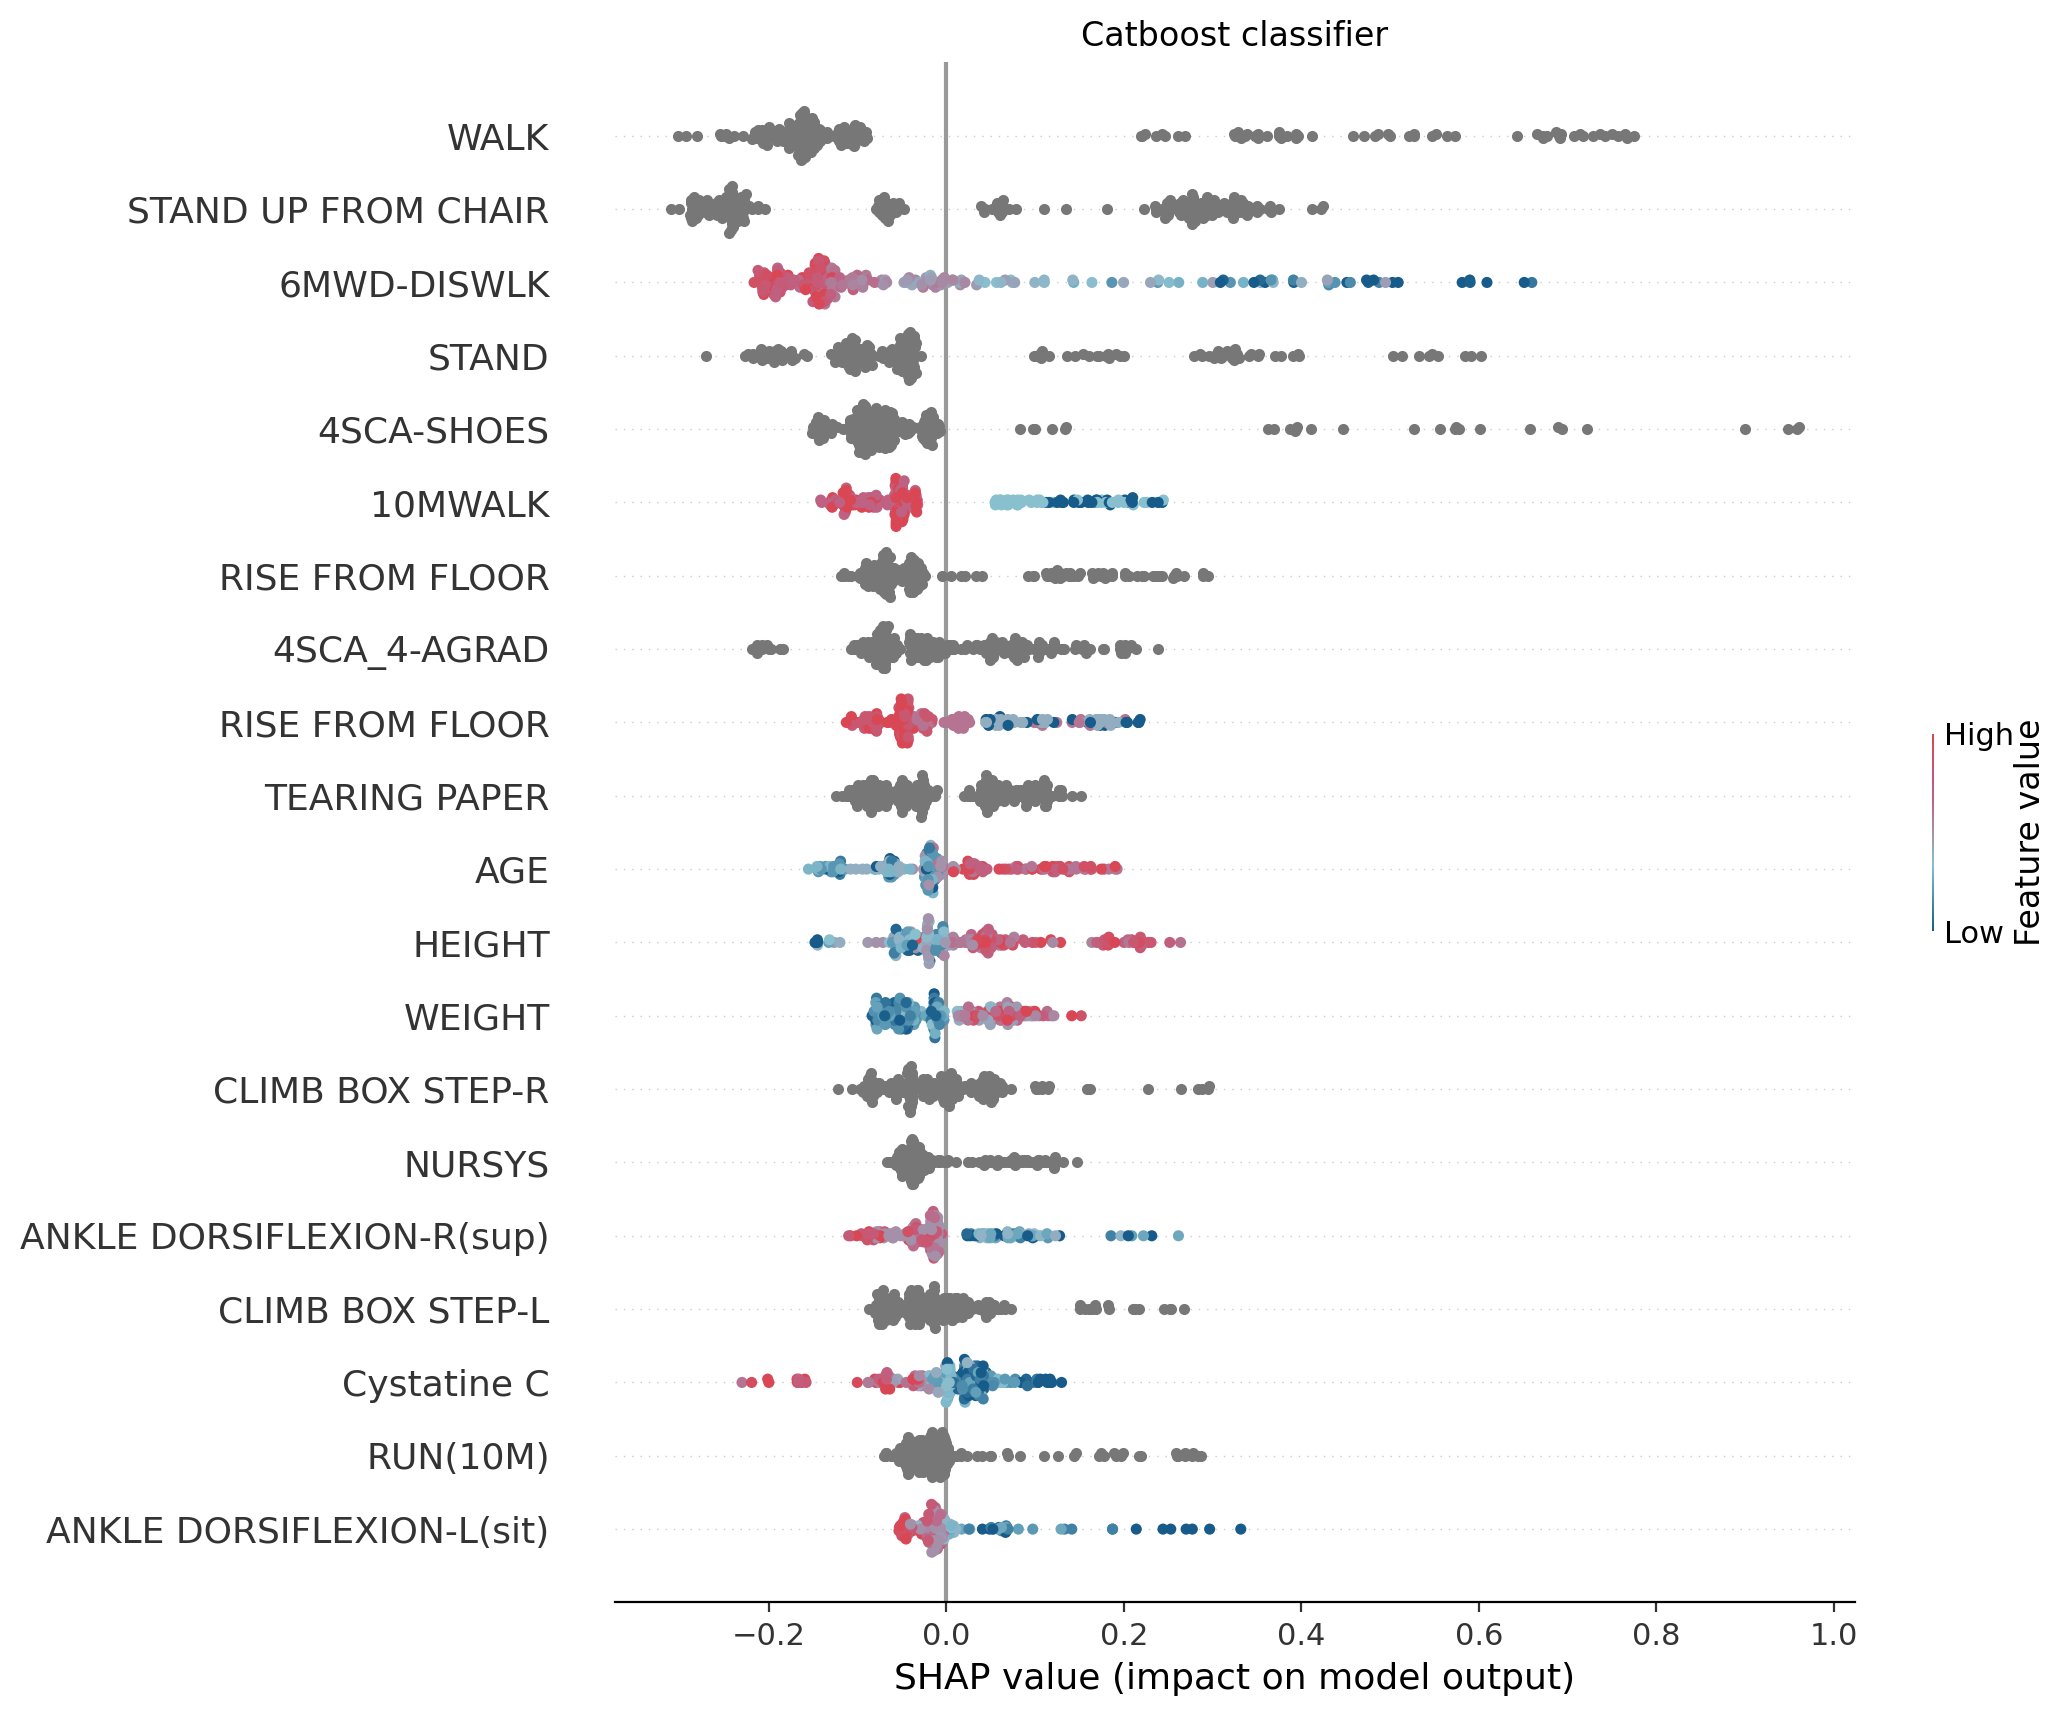

In [9]:
fig = plt.figure()
shap.summary_plot(catboost_clf_shap_values, catboost_clf_x_test, 
                  show=False, 
                  cmap=plt.cm.get_cmap(custom_cmap))
plt.gcf().set_size_inches(10,10)
plt.title('Catboost classifier')
plt.show()

### Regressor

In [10]:
(catboost_reg_shap, 
catboost_reg_shap_0, catboost_reg_shap_1, catboost_reg_shap_2, catboost_reg_shap_3, catboost_reg_shap_4, 
catboost_reg_df, catboost_reg_summary_df) = shap_values_feature_importance('catboost_reg',5)  

In [11]:
catboost_reg_summary_df

,fold_1,fold_2,fold_3,fold_4,fold_5,sum
Features,,,,,,
RISE FROM FLOOR,1,1,1,1,1,5
10MWALK,1,1,1,1,1,5
WALK,0,1,1,1,1,4
RISE_FROM_FLOOR,1,1,1,0,1,4
LVEF,1,0,1,0,1,3
LEFT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY),0,0,1,0,1,2
STAND UP FROM CHAIR,1,0,1,0,0,2
STEROID_CM,0,0,0,1,1,2
SUPINATION,1,0,1,0,0,2


In [12]:
cat_clf = set(catboost_clf_summary_df.head(10).index.tolist())
cat_reg = set(catboost_reg_summary_df.head(10).index.tolist())

In [13]:
catboost_reg_shap_values, catboost_reg_x_test = concatenate('catboost_reg', 5)

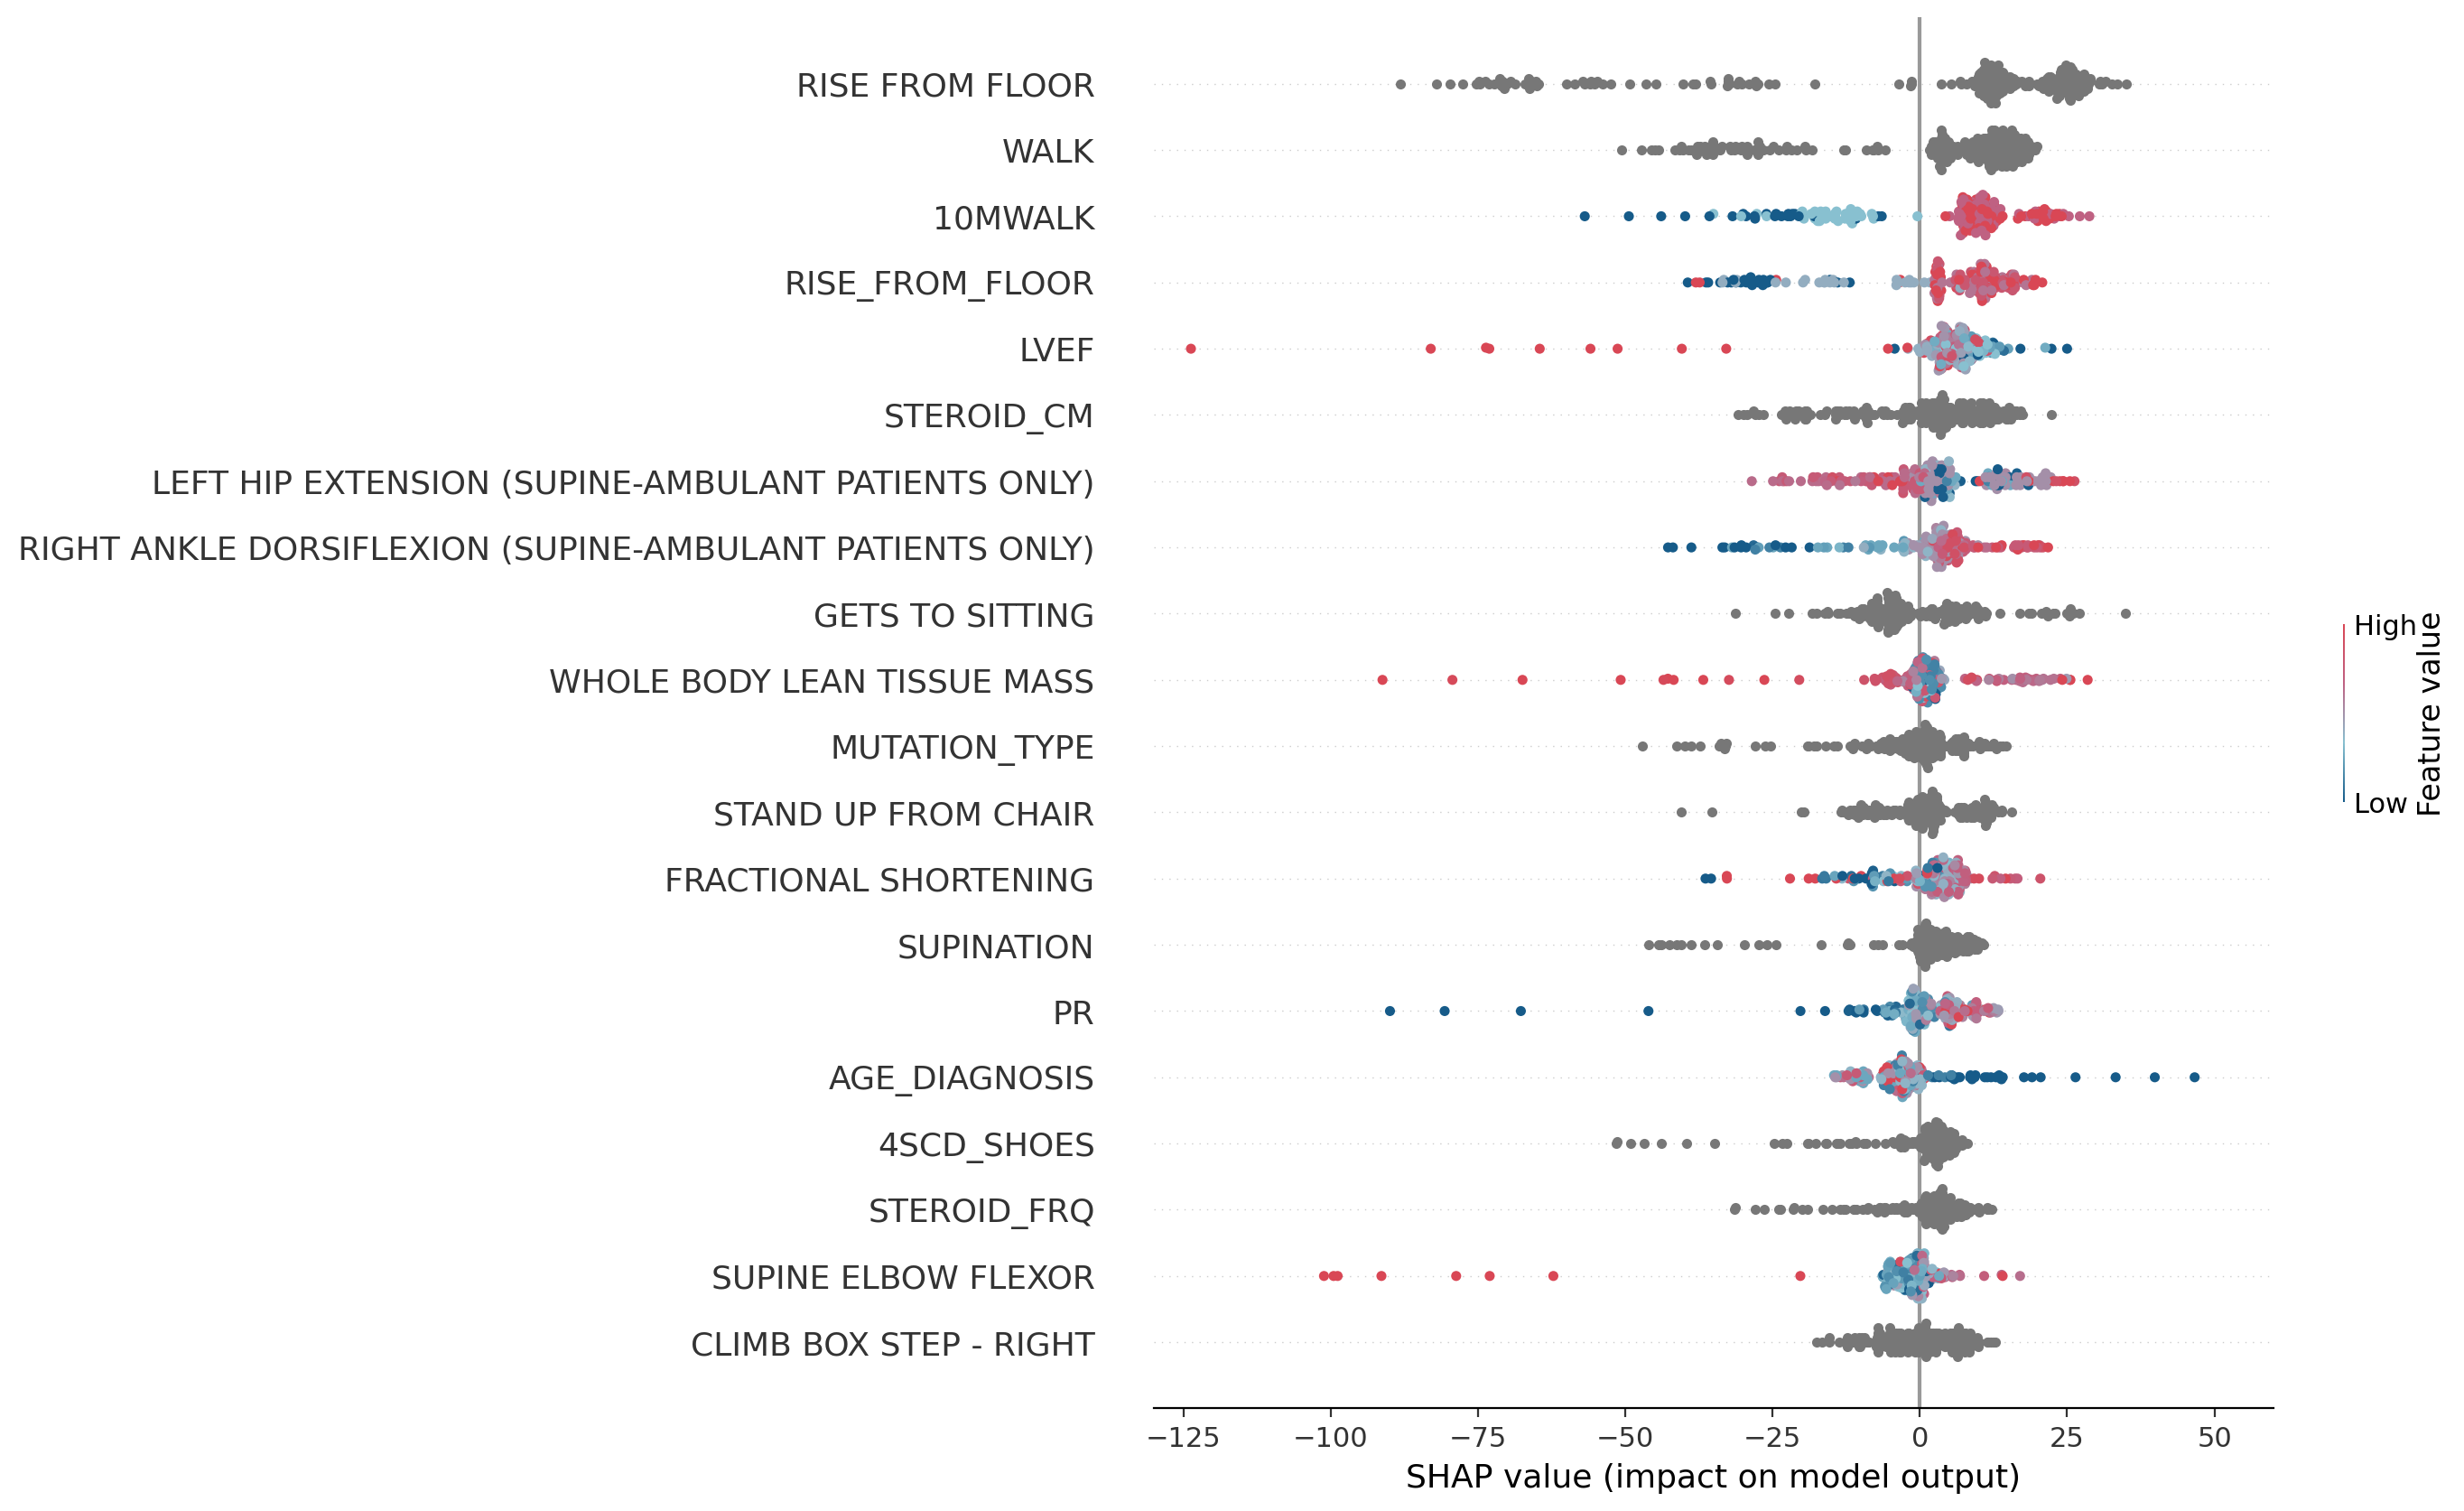

In [14]:
fig = plt.figure()

shap.summary_plot(catboost_reg_shap_values, catboost_reg_x_test, cmap=custom_cmap, show=False)
plt.gcf().set_size_inches(10,10)
plt.xlim(-130, 60)
plt.show()

In [15]:
catboost_reg_x_test = catboost_reg_x_test.rename(columns={'WALK_2= WALKS WITH HEEL-TOE OR FLAT-FOOTED GAIT PATTERN':'WALK-2', 
                                        'STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS':'STAND-2', 
                                        'RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE': 'RISE FROM FLOOR-0', 
                                        'STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP': 'STAND UP FROM CHAIR-2', 
                                        'WALK_1= PERSISTENT OR HABITUAL TOE WALKER, UNABLE TO HEEL-TOE CONSISTENTLY':'WALK-1', 
                                        'RISE FROM FLOOR_1= GOWERS EVIDENT': 'RISE FROM FLOOR-1',
                                        'LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)': 'ANKLE DORSIFLEXION-L(sup)',
                                        'RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)': 'ANKLE DORSIFLEXION-R(sup)', 
                                        'STAND_1= STANDS STILL BUT WITH SOME DEGREE OF COMPENSATION (E.G. ON TOES OR WITH LEGS ABDUCTED OR WITH BOTTOM STUCK OUT) FOR MINIMUM COUNT OF 3 SECONDS': 'STAND-1', 
                                        'LEFT ANKLE DORSIFLEXION (SITTING)': 'ANKLE DORSIFLEXION-L(sit)',  
                                        'DESCEND BOX STEP - LEFT_0= UNABLE': 'DESCEND BOX STEP-L-0', 
                                        'RISE_FROM_FLOOR': 'RISE FROM FLOOR', 
                                        '6MWD_DISWLK': '6MWD-DISWLK', 
                                        'CURRENT_AGE': 'AGE',
                                        '4SCD_4-AGRAD': '4SCD 4-AGRAD',
                                        'CLIMB BOX STEP - RIGHT': 'CLIMB BOX STEP-R',
                                        'CLIMB BOX STEP - LEFT': 'CLIMB BOX STEP-L',
                                        '4SCA_SHOES': '4SCA-SHOES',
                                        'STEROID_CM': 'STEROID CM',
                                        'AGE_DIAGNOSIS': 'AGE DIAGNOSIS',
                                        'MUTATION_TYPE': 'MUTATION TYPE',
                                        'LEFT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY)': 'HIP EXTENSION-L(sup)'
                                                         })

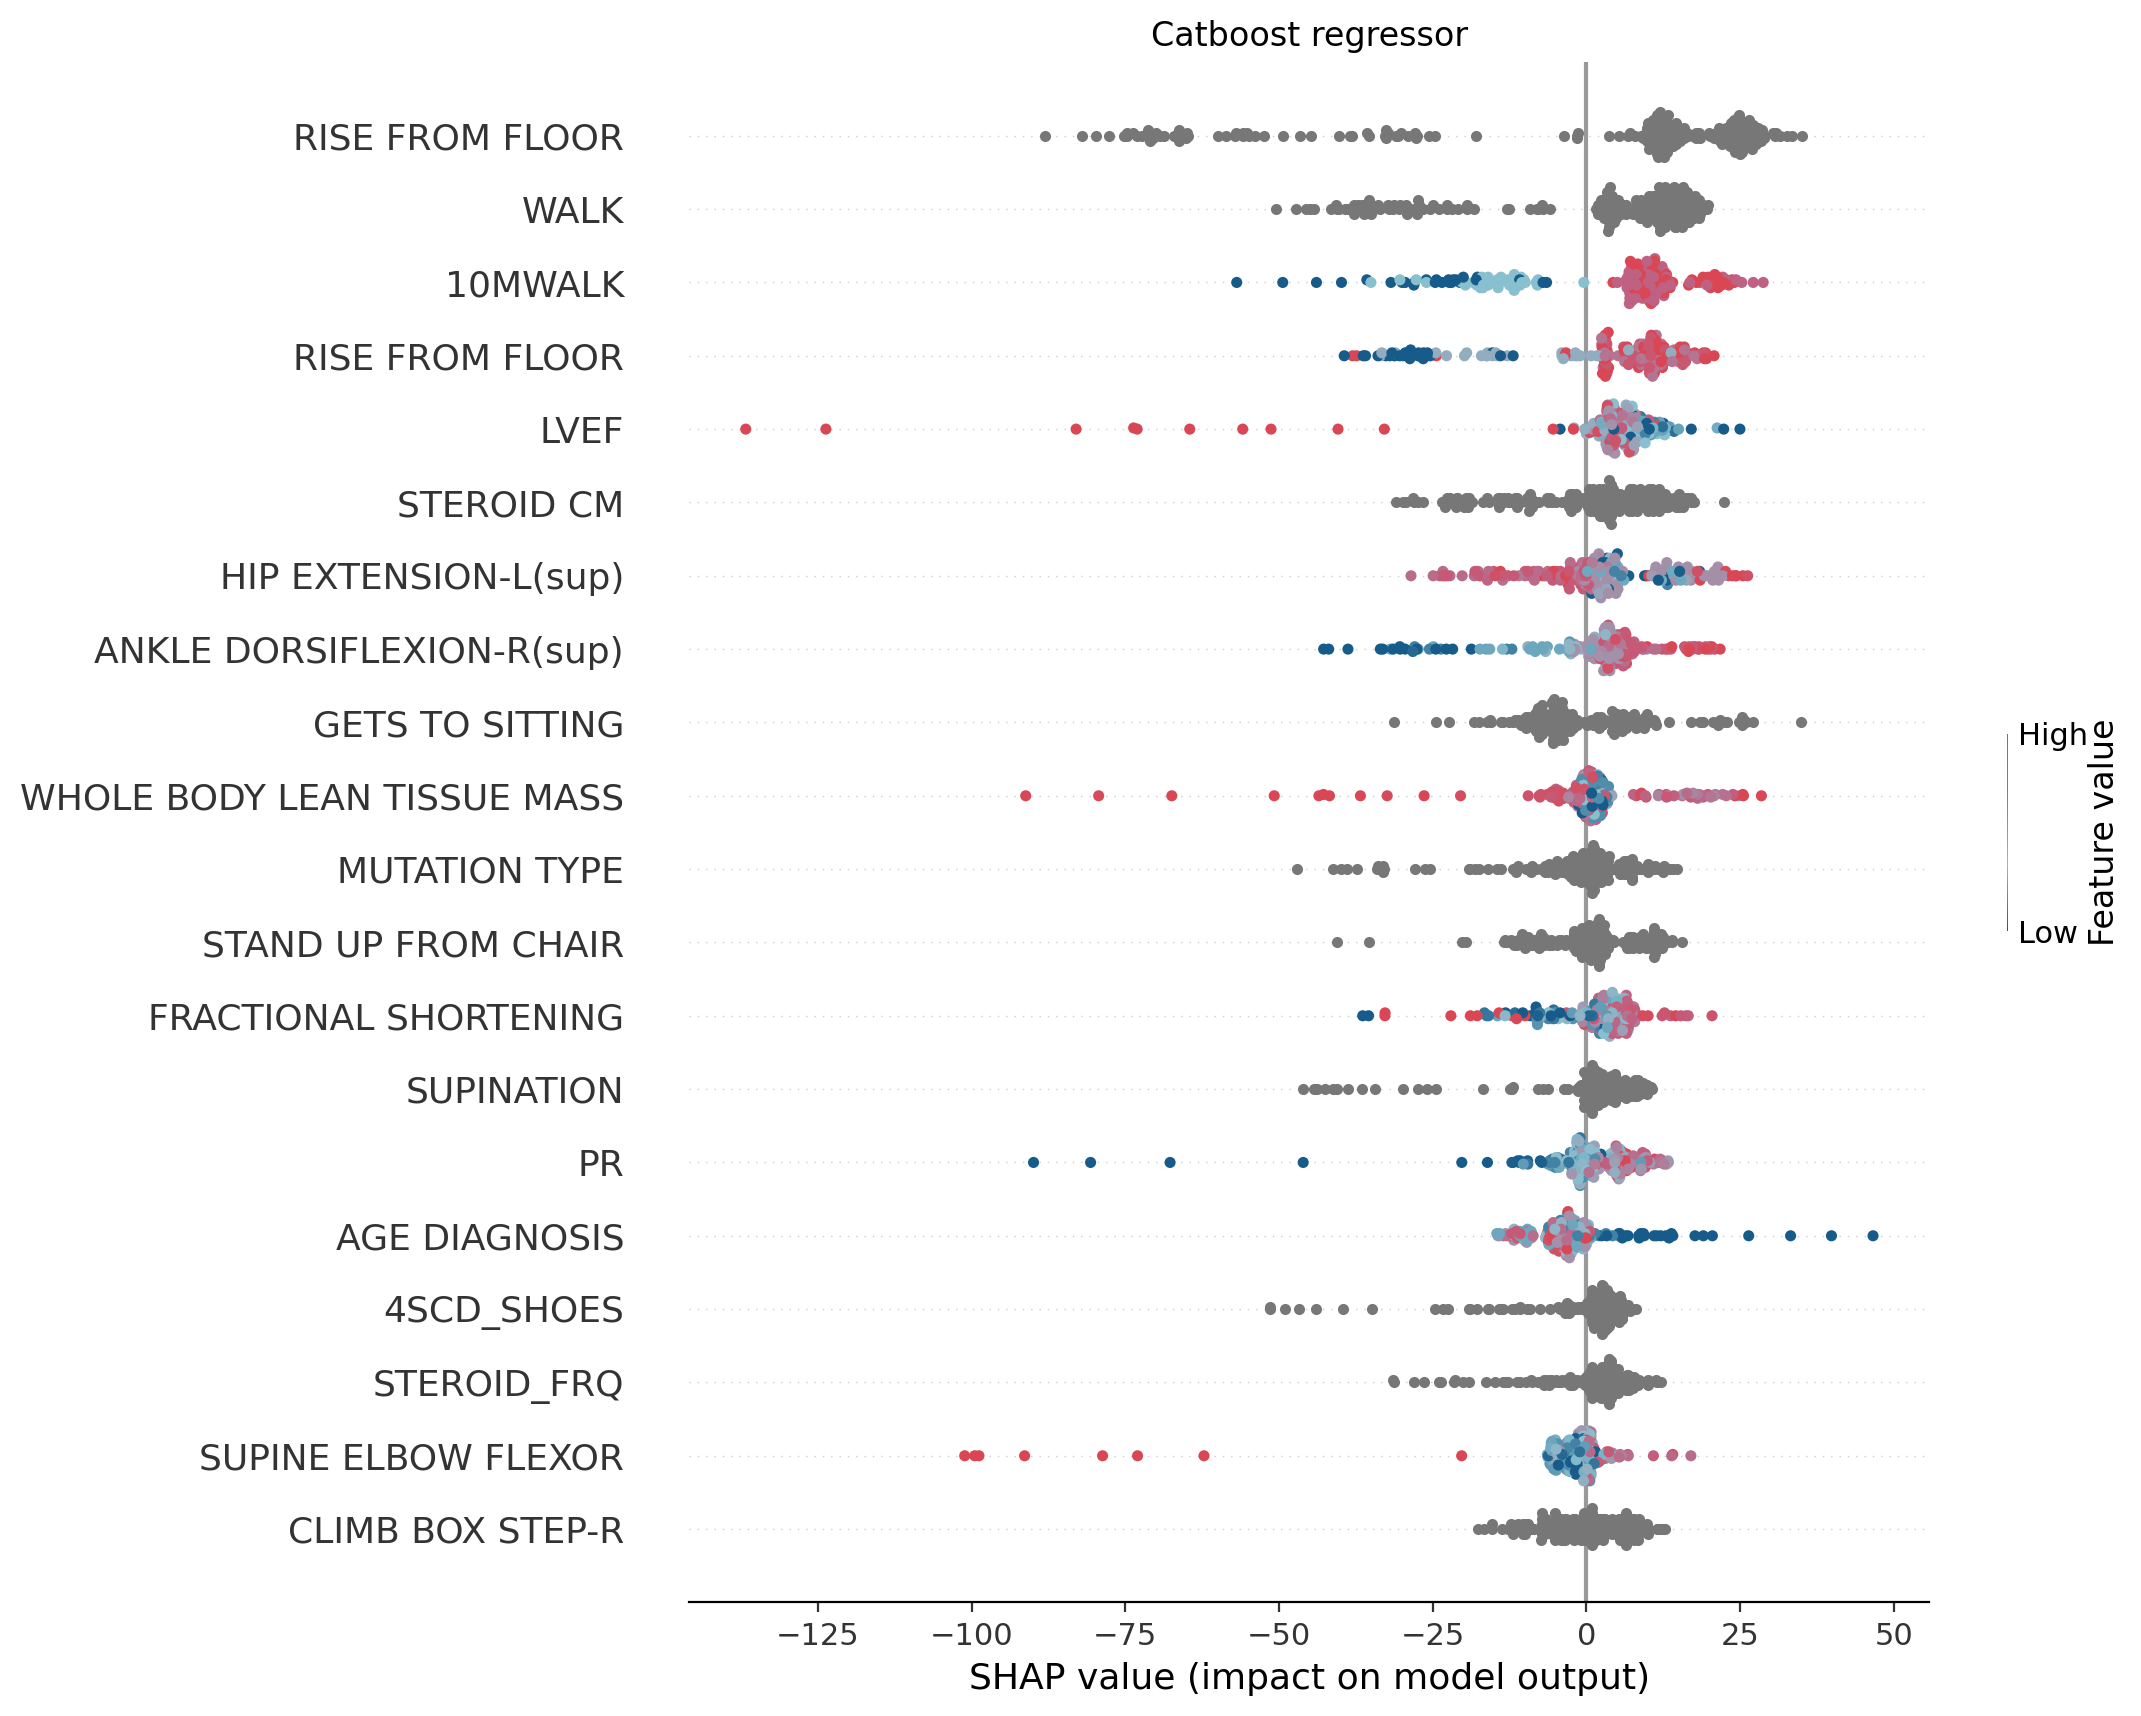

In [16]:
fig = plt.figure()
shap.summary_plot(catboost_reg_shap_values, catboost_reg_x_test, 
                  show=False, 
                  cmap=plt.cm.get_cmap(custom_cmap)) 
#                   color_bar=False)
plt.gcf().set_size_inches(10,10)
plt.title('Catboost regressor')
plt.show()

## CoxPH EN

In [17]:
(coxph_shap, 
 coxph_shap_0, coxph_shap_1, coxph_shap_2, coxph_shap_3, coxph_shap_4, 
 coxph_df, coxph_summary_df) = shap_values_feature_importance('coxph',5)

In [18]:
coxph_summary_df

,fold_1,fold_2,fold_3,fold_4,fold_5,sum
Features,,,,,,
Complement C3c,1,1,1,1,1,5
Cystatine C,1,1,1,1,1,5
MUTATION_TYPE_DELETION,1,1,1,1,1,5
WHOLE BODY FAT TISSUE MASS,1,1,1,1,1,5
MHINT_bin,1,1,1,1,1,5
ETHNIC_NOT_HISPANIC_LATINO,1,1,1,1,1,5
ETHNIC_HISPANIC_LATINO,1,1,1,1,1,5
ETHNIC_UNKNOWN,1,1,1,1,1,5
WHOLE BODY LEAN TISSUE MASS,1,1,0,1,0,3


In [19]:
coxph = set(coxph_summary_df.head(10).index.tolist())

In [20]:
coxnet_shap_values, coxnet_x_test = concatenate('coxph', 5)

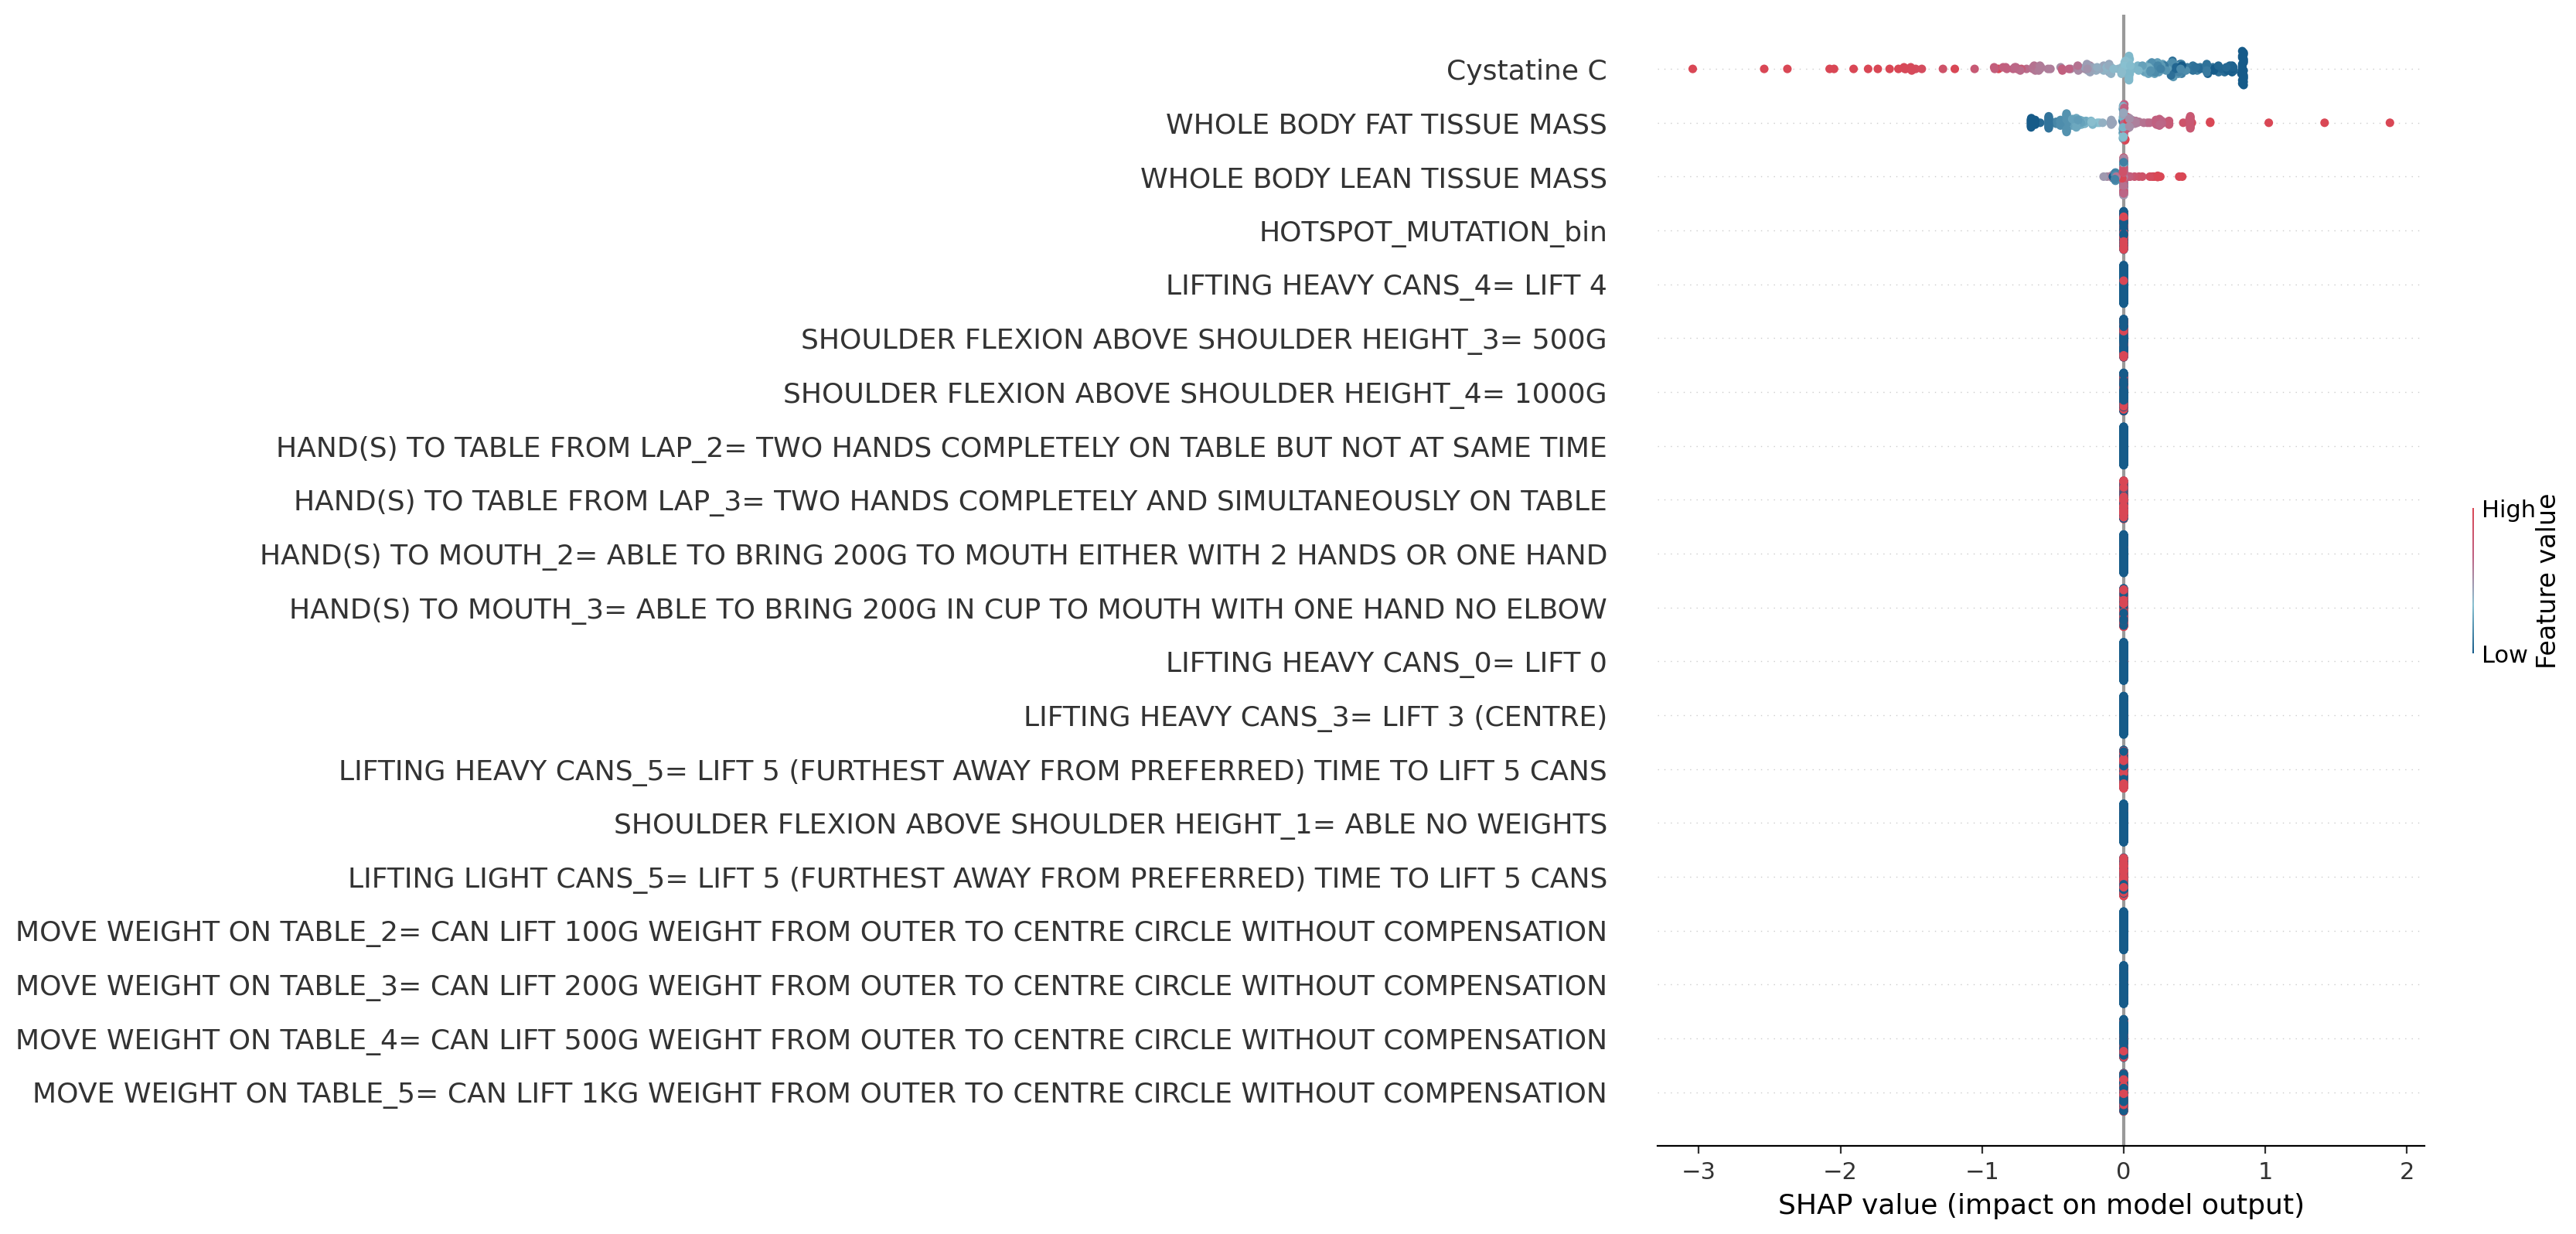

In [21]:
shap.summary_plot(coxnet_shap_values, coxnet_x_test, cmap=custom_cmap, show=False)

In [22]:
coxnet_x_test = coxnet_x_test.rename(columns={
'HOTSPOT_MUTATION_bin': 'HOTSPOT MUTATION',
'LIFTING HEAVY CANS_4= LIFT 4': 'LIFTING HEAVY CANS-4',
'HAND(S) TO TABLE FROM LAP_2= TWO HANDS COMPLETELY ON TABLE BUT NOT AT SAME TIME': 'HAND(S) TO TABLE FROM LAP-2',
'HAND(S) TO TABLE FROM LAP_3= TWO HANDS COMPLETELY AND SIMULTANEOUSLY ON TABLE': 'HAND(S) TO TABLE FROM LAP-3',
'HAND(S) TO MOUTH_2= ABLE TO BRING 200G TO MOUTH EITHER WITH 2 HANDS OR ONE HAND': 'HAND(S) TO MOUTH-2',
'HAND(S) TO MOUTH_3= ABLE TO BRING 200G IN CUP TO MOUTH WITH ONE HAND NO ELBOW': 'HAND(S) TO MOUTH-3',
'SHOULDER FLEXION ABOVE SHOULDER HEIGHT_1= ABLE NO WEIGHTS': 'SHOULDER FLEXION ABOVE SHOULDER HEIGHT-1',
'SHOULDER FLEXION ABOVE SHOULDER HEIGHT_3= 500G': 'SHOULDER FLEXION ABOVE SHOULDER HEIGHT-3',
'SHOULDER FLEXION ABOVE SHOULDER HEIGHT_4= 1000G': 'SHOULDER FLEXION ABOVE SHOULDER HEIGHT-4',
'LIFTING HEAVY CANS_0= LIFT 0': 'LIFTING HEAVY CANS-0',
'LIFTING HEAVY CANS_3= LIFT 3 (CENTRE)': 'LIFTING HEAVY CANS-3',
'LIFTING HEAVY CANS_5= LIFT 5 (FURTHEST AWAY FROM PREFERRED) TIME TO LIFT 5 CANS': 'LIFTING HEAVY CANS-5',
'LIFTING LIGHT CANS_5= LIFT 5 (FURTHEST AWAY FROM PREFERRED) TIME TO LIFT 5 CANS': 'LIFTING LIGHT CANS-5',
'MOVE WEIGHT ON TABLE_2= CAN LIFT 100G WEIGHT FROM OUTER TO CENTRE CIRCLE WITHOUT COMPENSATION': 'MOVE WEIGHT ON TABLE-2',
'MOVE WEIGHT ON TABLE_3= CAN LIFT 200G WEIGHT FROM OUTER TO CENTRE CIRCLE WITHOUT COMPENSATION': 'MOVE WEIGHT ON TABLE-3',
'MOVE WEIGHT ON TABLE_4= CAN LIFT 500G WEIGHT FROM OUTER TO CENTRE CIRCLE WITHOUT COMPENSATION': 'MOVE WEIGHT ON TABLE-4',
'MOVE WEIGHT ON TABLE_5= CAN LIFT 1KG WEIGHT FROM OUTER TO CENTRE CIRCLE WITHOUT COMPENSATION': 'MOVE WEIGHT ON TABLE-5',
})

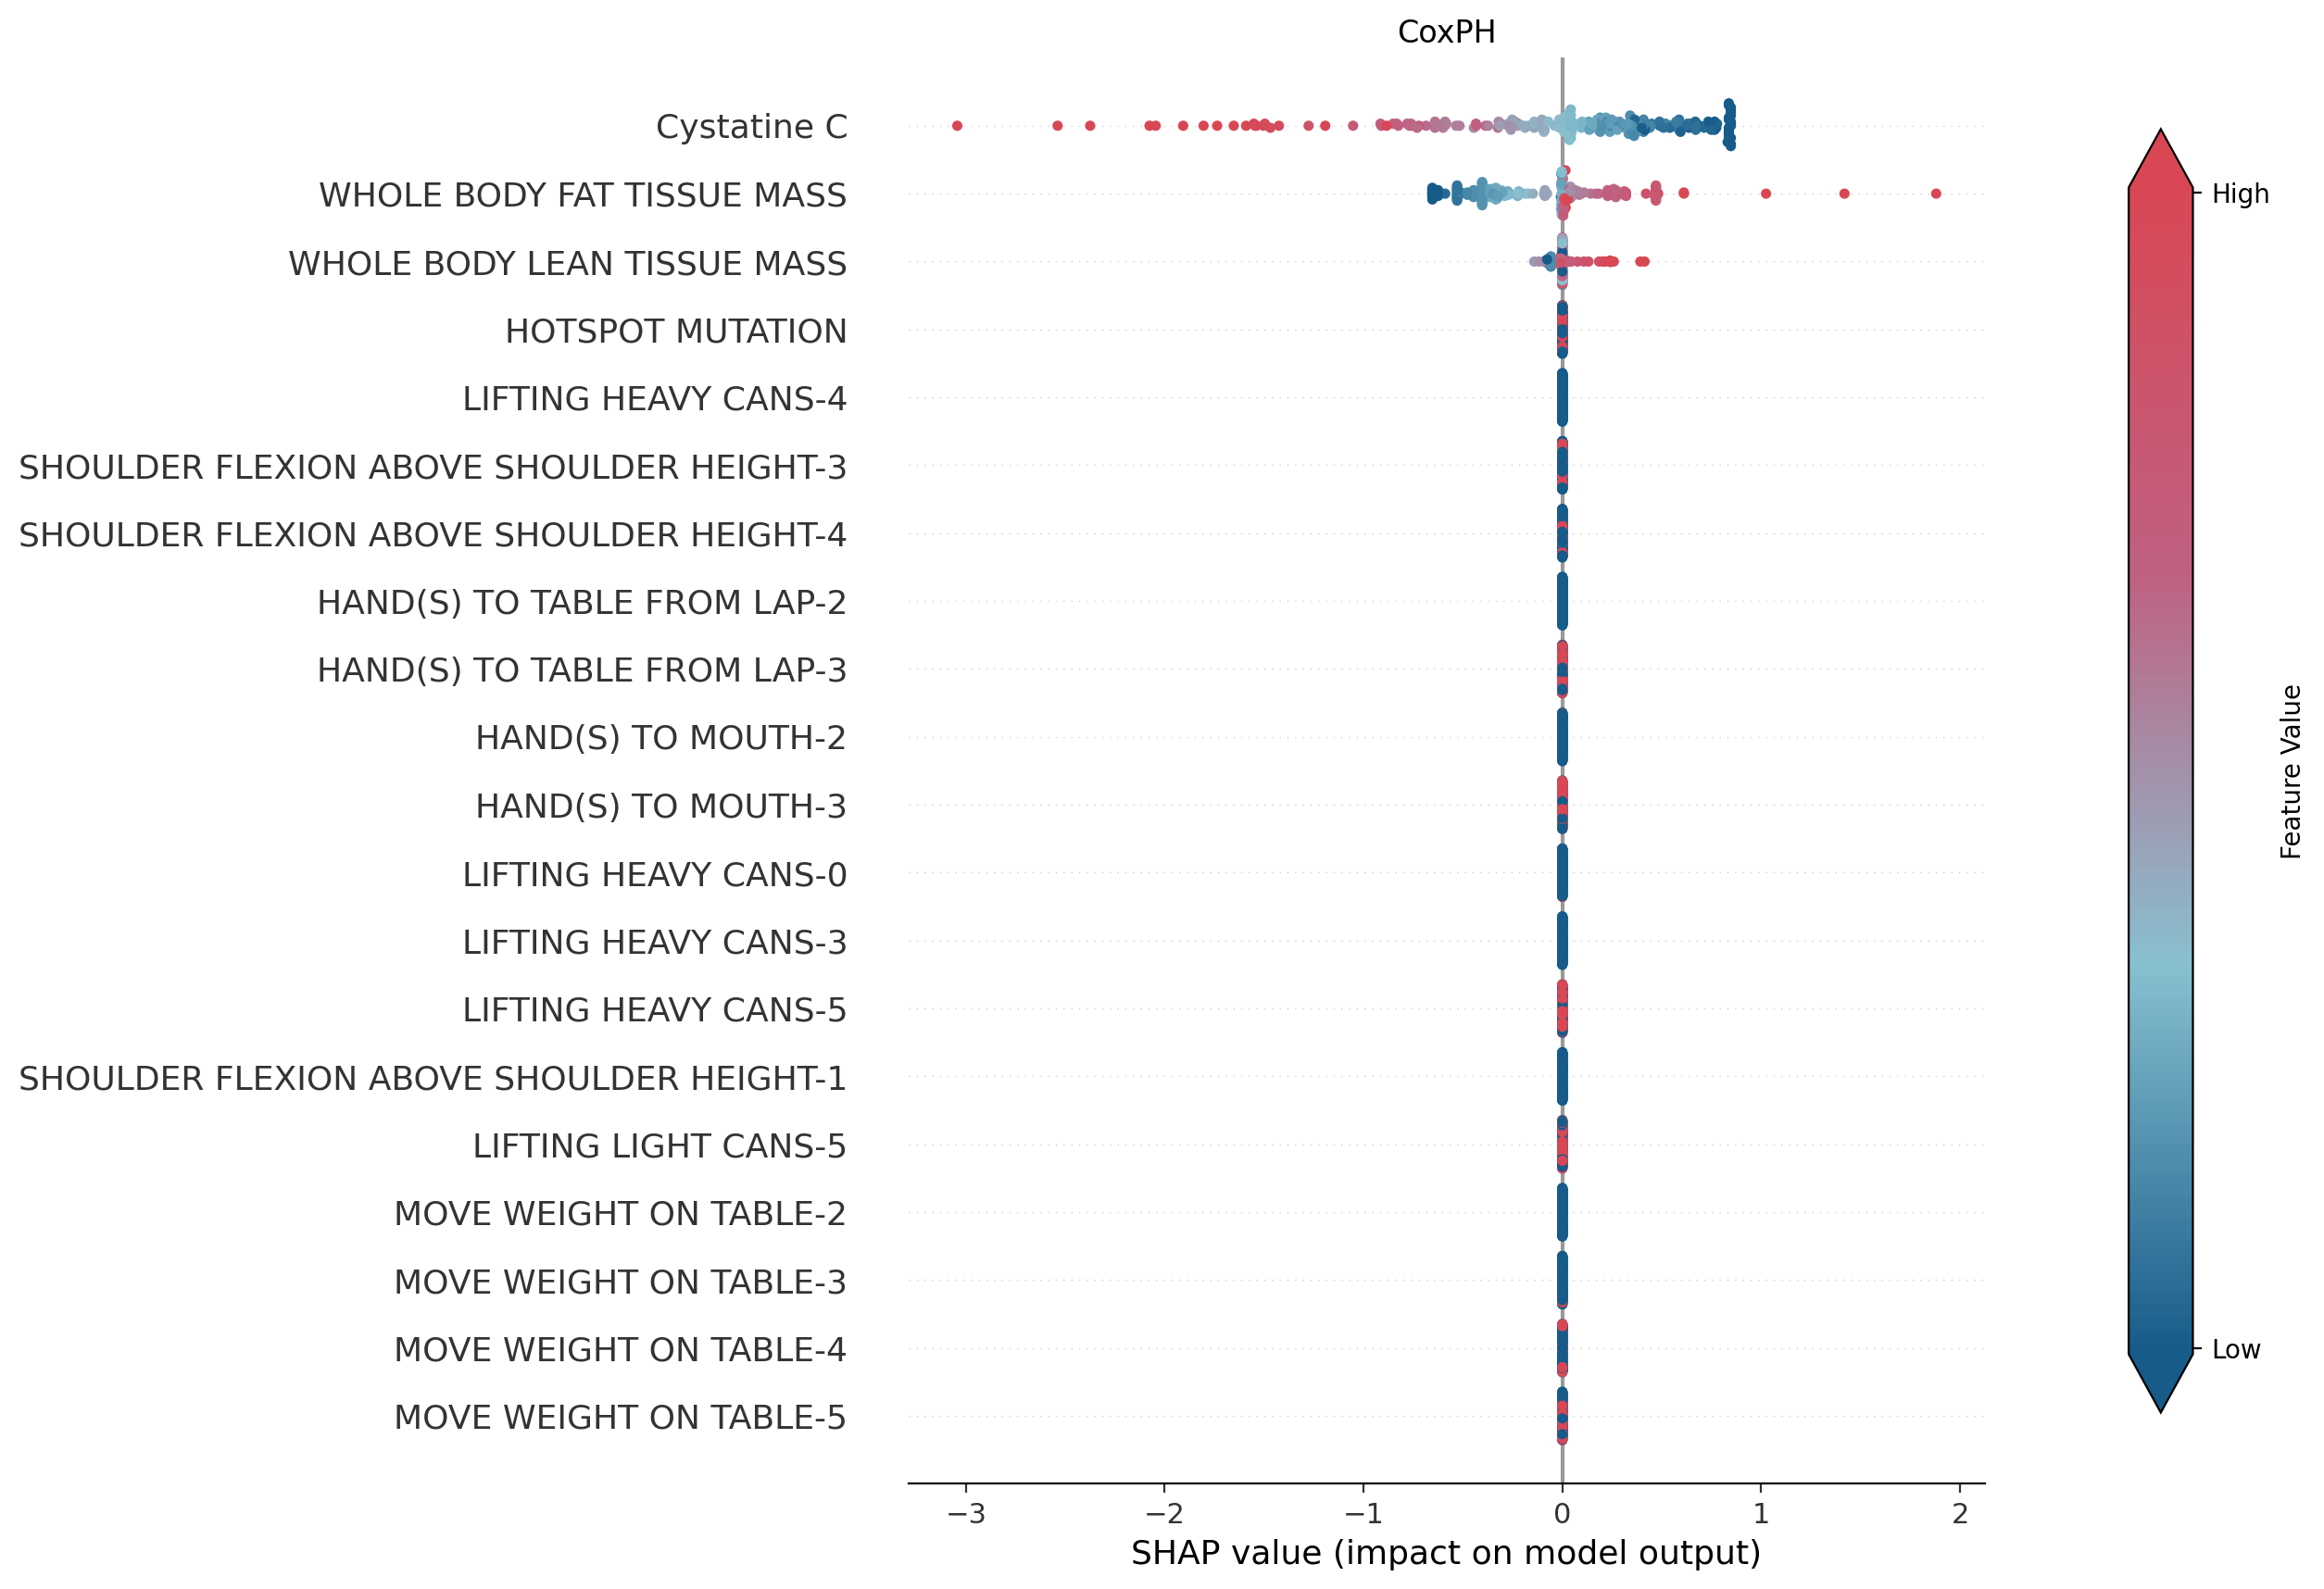

In [23]:
fig = plt.figure()
shap.summary_plot(coxnet_shap_values, coxnet_x_test, show=False, cmap=plt.cm.get_cmap(custom_cmap), color_bar=False)
plt.gcf().set_size_inches(10,10)
plt.title('CoxPH')
cbar = plt.colorbar(label='Feature Value',  
                    extend='both',
                    pad=0.1, 
                    shrink=0.9)
cbar.set_ticks([10000,175000])
cbar.set_ticklabels(["Low","High"])
plt.show()

## RSF

In [24]:
(rsf_shap, 
 rsf_shap_0, rsf_shap_1, rsf_shap_2, rsf_shap_3, rsf_shap_4, 
 rsf_df, rsf_summary_df) = shap_values_feature_importance('rsf',5)

In [25]:
rsf_summary_df

,fold_1,fold_2,fold_3,fold_4,fold_5,sum
Features,,,,,,
"STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS",1,1,1,1,1,5
10MWALK,1,1,1,1,1,5
6MWD_DISWLK,1,1,1,1,0,4
RISE_FROM_FLOOR,0,1,1,1,1,4
RISE FROM FLOOR_1= GOWERS EVIDENT,0,1,0,1,1,3
LEFT ANKLE DORSIFLEXION (SITTING),1,0,0,1,1,3
RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),1,0,0,1,0,2
WEIGHT,0,1,0,1,0,2
"WALK_1= PERSISTENT OR HABITUAL TOE WALKER, UNABLE TO HEEL-TOE CONSISTENTLY",0,0,1,1,0,2


In [26]:
rsf = set(rsf_summary_df.head(20).index.tolist())

In [27]:
rsf

{'10MWALK',
 '6MWD_DISWLK',
 'CURRENT_AGE',
 'FVC',
 'HEIGHT',
 'KNEE EXTENSOR',
 'LEFT ANKLE DORSIFLEXION (SITTING)',
 'LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)',
 'NSAA',
 'RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)',
 'RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE',
 'RISE FROM FLOOR_1= GOWERS EVIDENT',
 'RISE_FROM_FLOOR',
 'STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP',
 'STAND_1= STANDS STILL BUT WITH SOME DEGREE OF COMPENSATION (E.G. ON TOES OR WITH LEGS ABDUCTED OR WITH BOTTOM STUCK OUT) FOR MINIMUM COUNT OF 3 SECONDS',
 'STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS',
 'SUPINE ELBOW EXTENSOR',
 'WALK_1= PERSISTENT OR HABITUAL TOE WALKER, UNABLE TO HEEL-TOE CONSISTENTLY',
 'WALK_2= WALKS WITH HEEL-TOE OR FLAT-FOOTED GAIT PATTERN',
 'WEIGHT'}

In [28]:
rsf_shap_values, rsf_x_test = concatenate('rsf', 5)

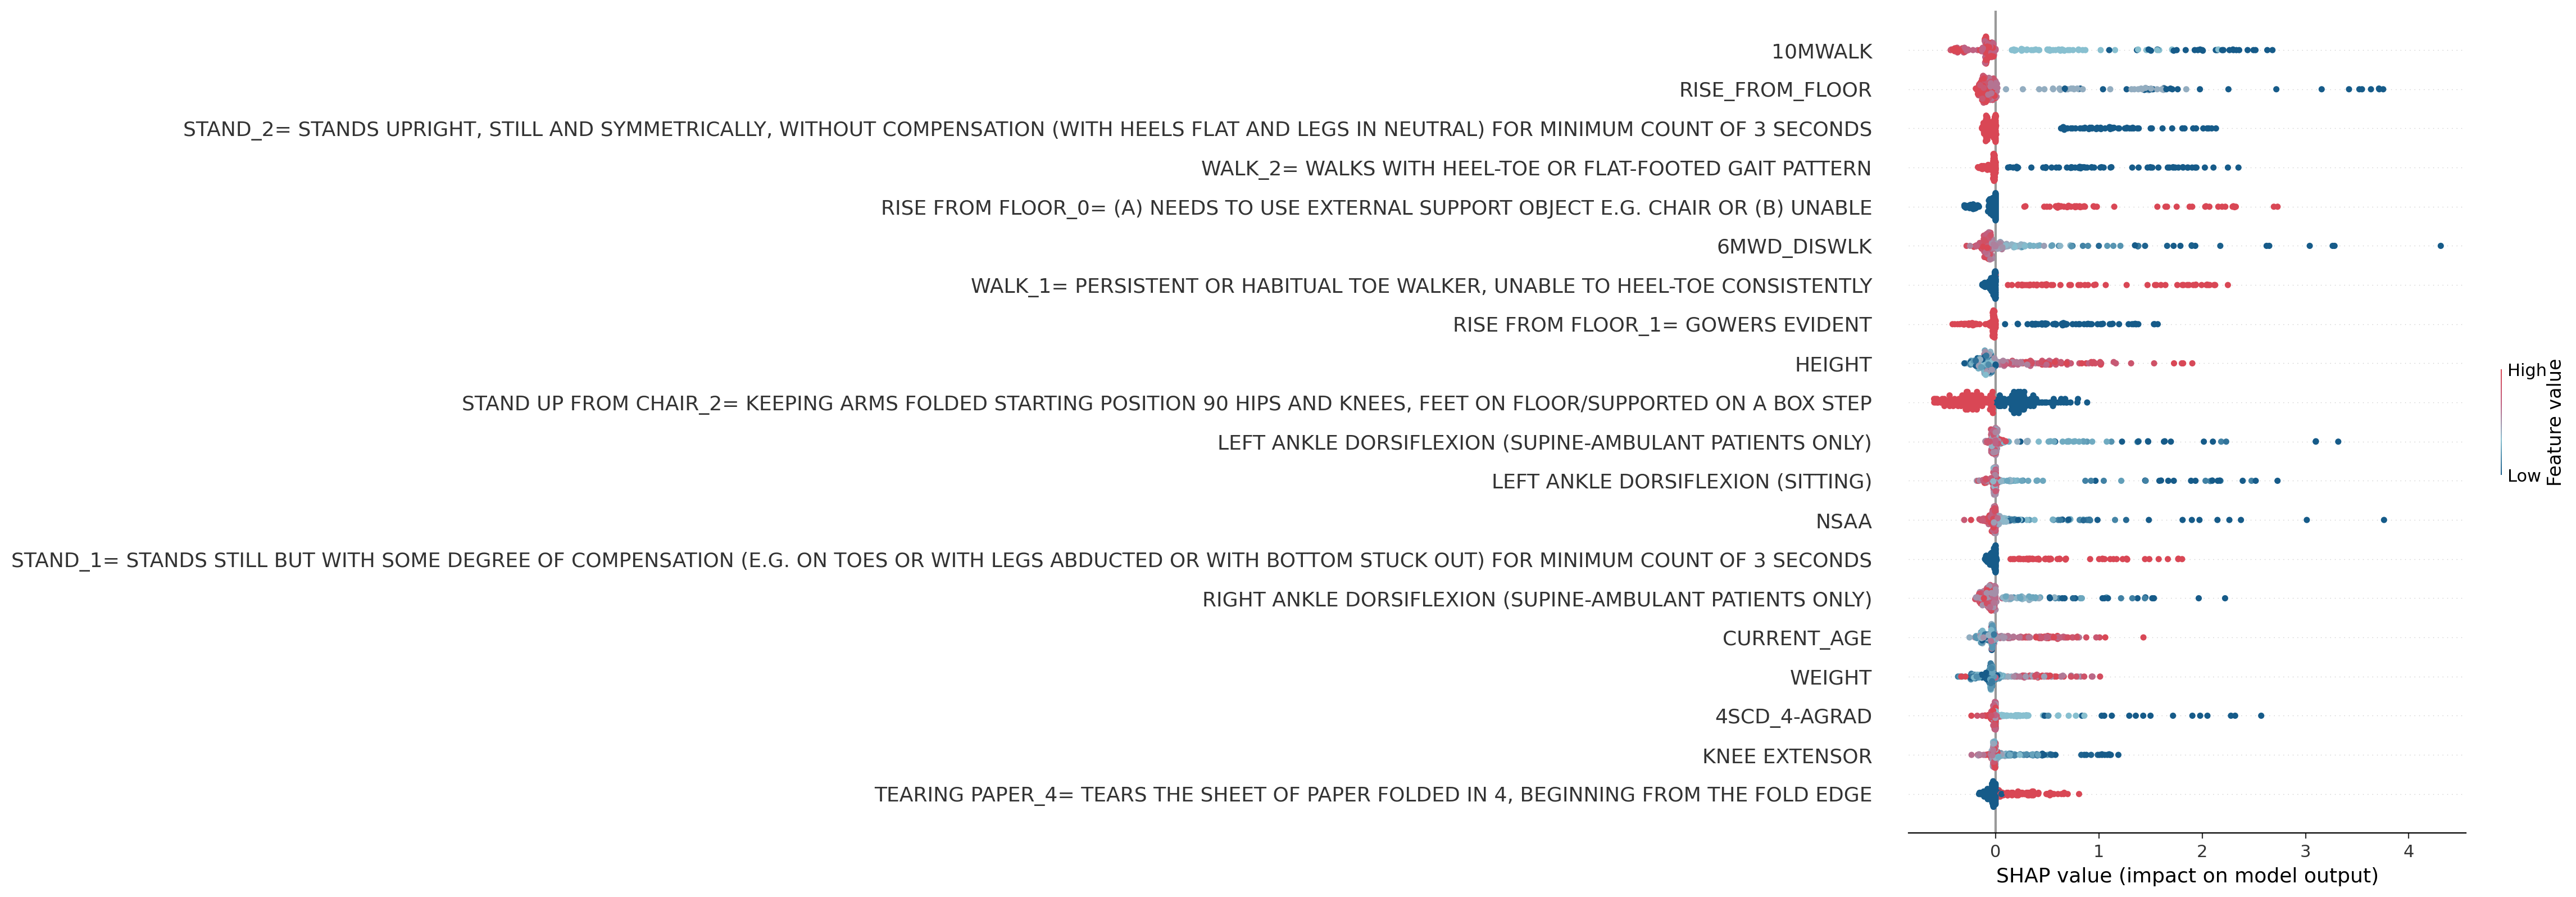

In [29]:
shap.summary_plot(rsf_shap_values, rsf_x_test, cmap=custom_cmap)

In [30]:
rsf_x_test = rsf_x_test.rename(columns={'WALK_2= WALKS WITH HEEL-TOE OR FLAT-FOOTED GAIT PATTERN':'WALK-2', 
                                        'STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS':'STAND-2', 
                                        'RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE': 'RISE FROM FLOOR-0', 
                                        'STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP': 'STAND UP FROM CHAIR-2', 
                                        'WALK_1= PERSISTENT OR HABITUAL TOE WALKER, UNABLE TO HEEL-TOE CONSISTENTLY':'WALK-1', 
                                        'RISE FROM FLOOR_1= GOWERS EVIDENT': 'RISE FROM FLOOR-1',
                                        'LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)': 'ANKLE DORSIFLEXION-L(sup)',
                                        'RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)': 'ANKLE DORSIFLEXION-R(sup)', 
                                        'STAND_1= STANDS STILL BUT WITH SOME DEGREE OF COMPENSATION (E.G. ON TOES OR WITH LEGS ABDUCTED OR WITH BOTTOM STUCK OUT) FOR MINIMUM COUNT OF 3 SECONDS': 'STAND-1', 
                                        'LEFT ANKLE DORSIFLEXION (SITTING)': 'ANKLE DORSIFLEXION-L(sit)',  
                                        'DESCEND BOX STEP - LEFT_0= UNABLE': 'DESCEND BOX STEP-L-0', 
                                        'RISE_FROM_FLOOR': 'RISE FROM FLOOR', 
                                        '6MWD_DISWLK': '6MWD-DISWLK', 
                                        'CURRENT_AGE': 'AGE',
                                        '4SCD_4-AGRAD': '4SCD 4-AGRAD',
                                        'TEARING PAPER_4= TEARS THE SHEET OF PAPER FOLDED IN 4, BEGINNING FROM THE FOLD EDGE': 'TEARING PAPER_4'
                                        
                                       })

In [31]:
rsf_x_test.columns.tolist()

['Complement C3c',
 'Cystatin C',
 'High Sensitivity C-reactive Protein',
 'Monocyte Chemotactic Protein 1',
 'Albumin',
 'Alpha-1 Globulin',
 'Cystatine C',
 'Kidney Injury Molecule',
 'Protein',
 'Urine glucose',
 'PR',
 'QRS',
 'QT',
 'QTc',
 'NSAA',
 'BONE MINERAL CONTENT',
 'WHOLE BODY FAT TISSUE MASS',
 'WHOLE BODY LEAN TISSUE MASS',
 'FRACTIONAL SHORTENING',
 'LEFT POSTERIOR WALL THICKNESS',
 'LEFT SEPTUM WALL THICKNESS',
 'LV END DIASTOLIC DIAMETER',
 'LVEF',
 'LV END SYSTOLIC DIAMETER',
 'ANKLE DORSIFLEXION-L(sit)',
 'RIGHT ANKLE DORSIFLEXION (SITTING)',
 'ELBOW EXTENSION(LEFT)',
 'ELBOW EXTENSION (RIGHT)',
 'LEFT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY)',
 'RIGHT HIP EXTENSION (SUPINE-AMBULANT PATIENTS ONLY)',
 'LEFT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY)',
 'RIGHT ILIO TIBIAL BANDS (SUPINE-AMBULANT PATIENTS ONLY)',
 'LEFT KNEE EXTENSION (SITTING)',
 'RIGHT KNEE EXTENSION (SITTING)',
 'SHOULDER FLEXION (LEFT)',
 'SHOULDER FLEXION (RIGHT)',
 'WRIST EXTENSION (L

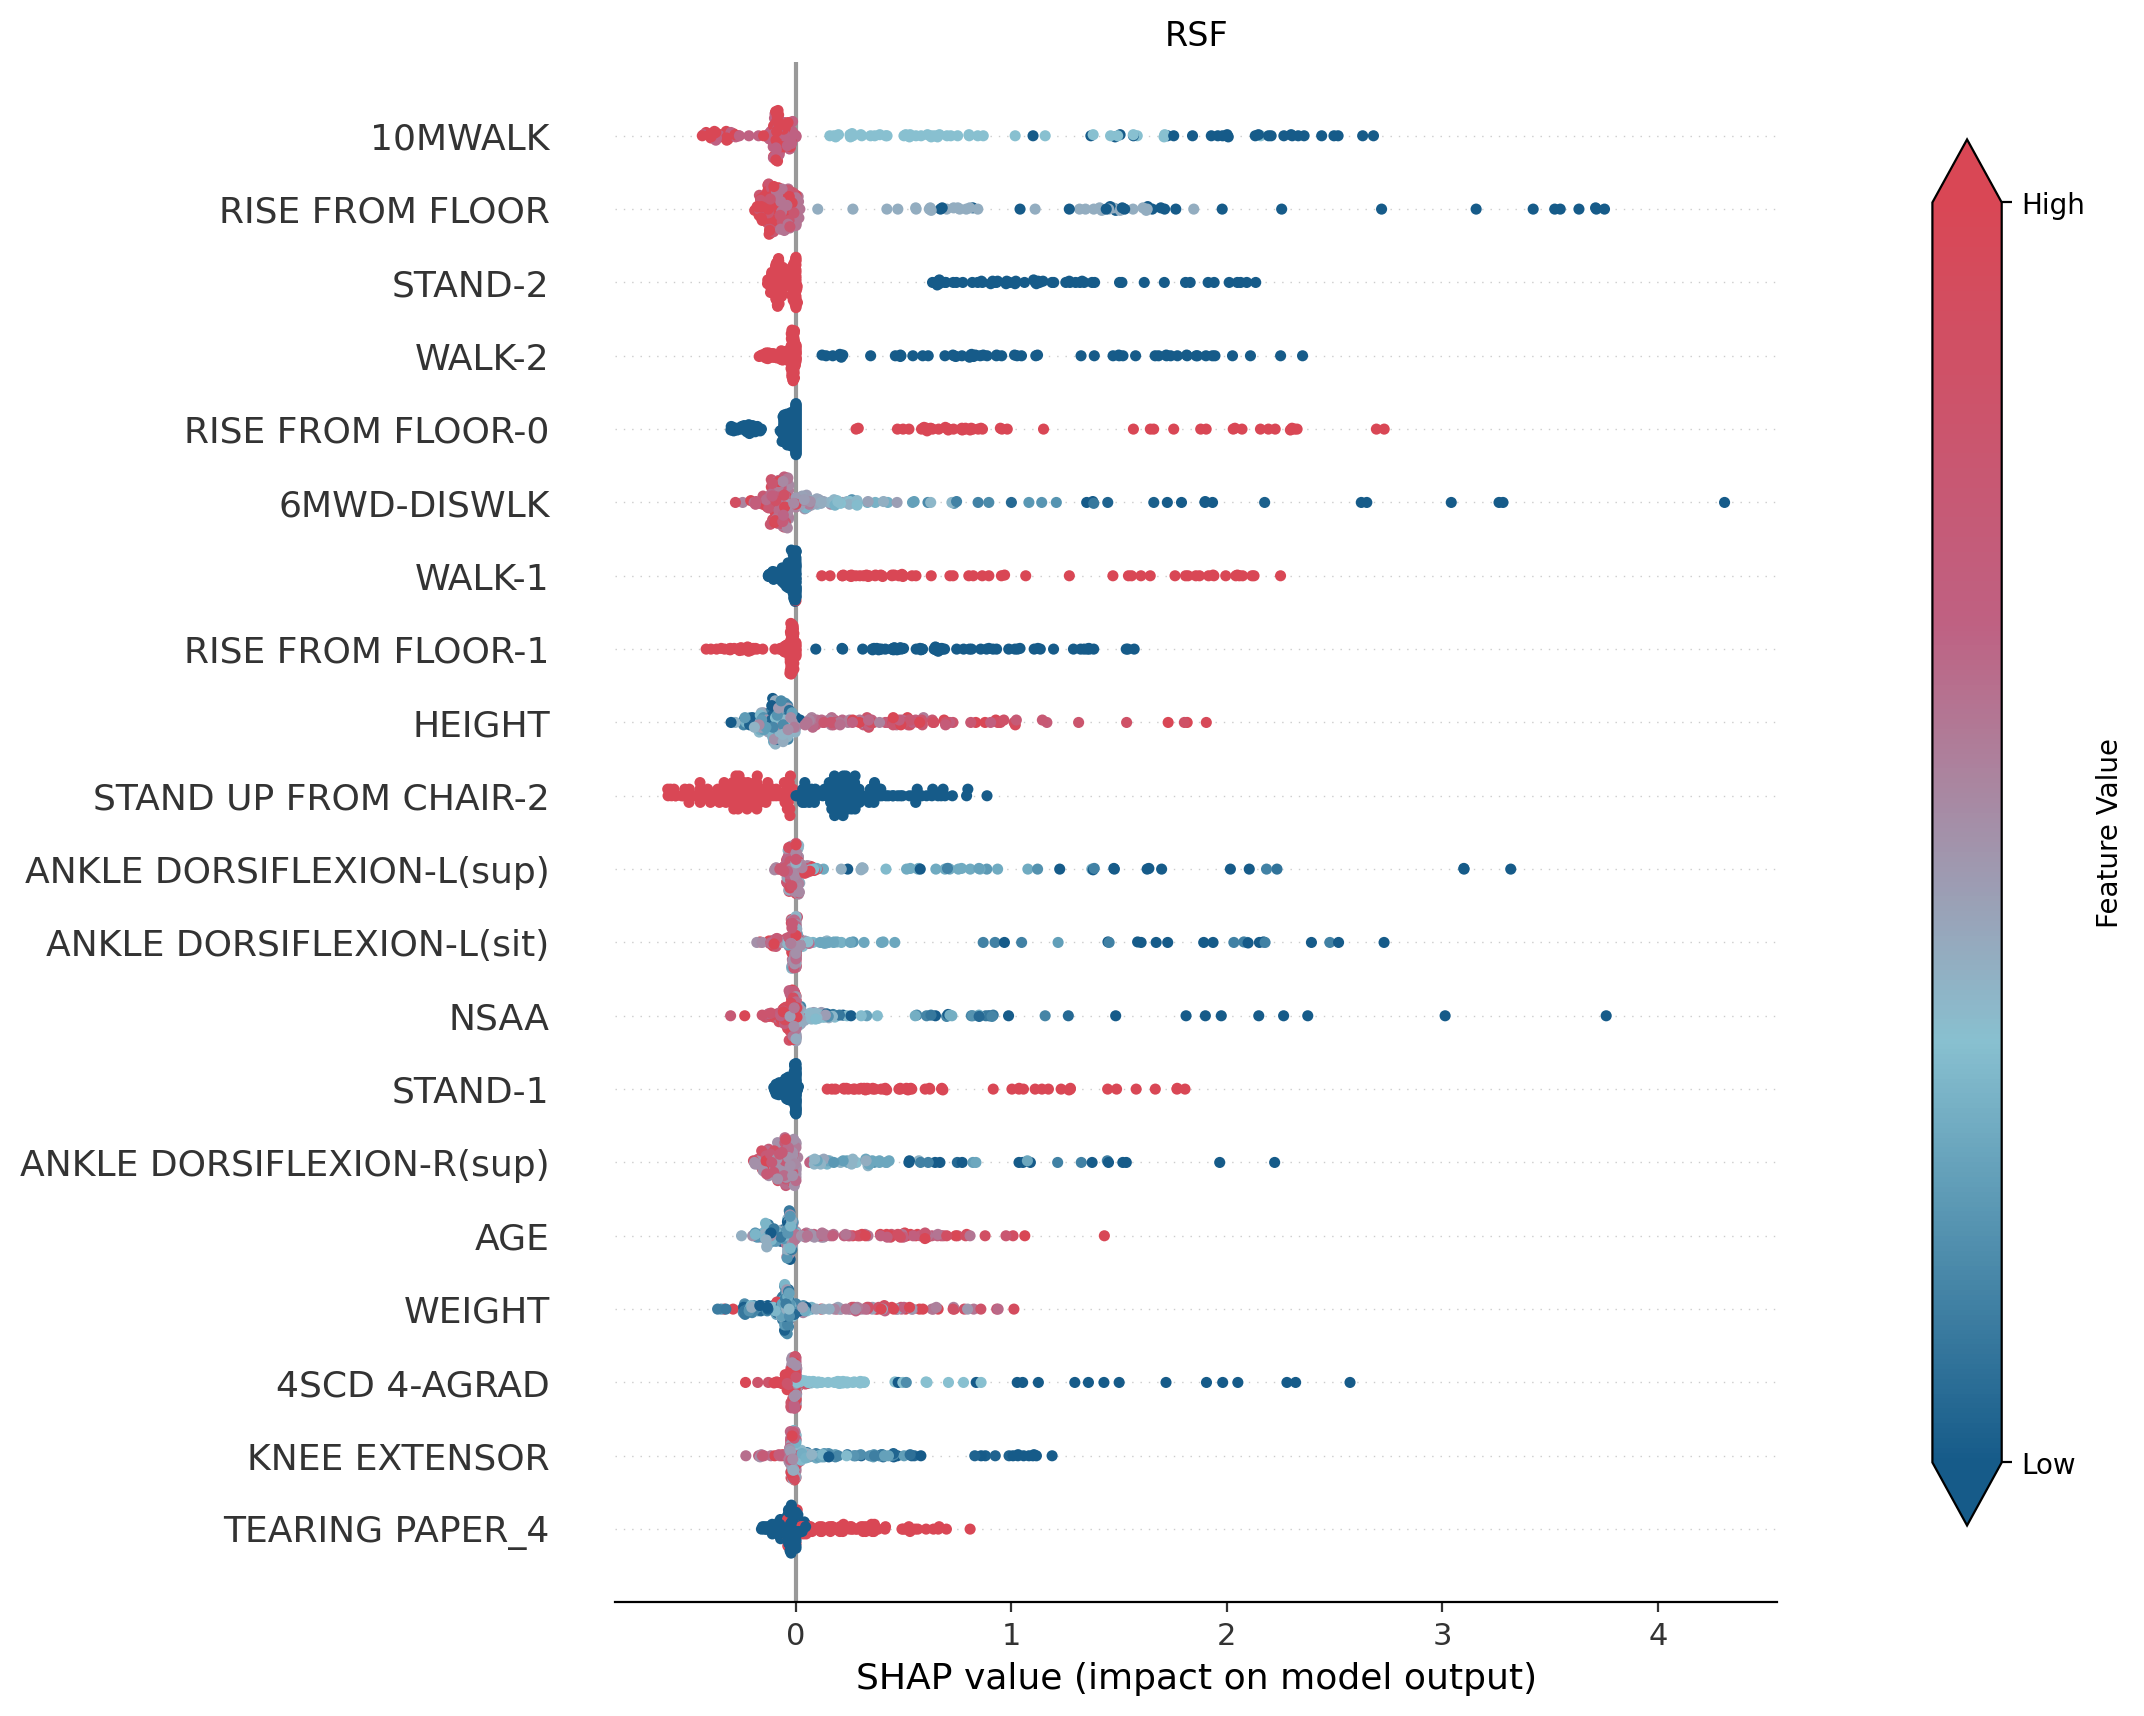

In [32]:
fig = plt.figure()
shap.summary_plot(rsf_shap_values, rsf_x_test, show=False, cmap=plt.cm.get_cmap(custom_cmap), color_bar=False)
plt.gcf().set_size_inches(10,10)
plt.title('RSF')
cbar = plt.colorbar(label='Feature Value',  
                    extend='both',
                    pad=0.1, 
                    shrink=0.9)
cbar.set_ticks([3,6])
cbar.set_ticklabels(["Low","High"])
plt.show()

## GBSA

In [33]:
(gbsa_shap, 
 gbsa_shap_0, gbsa_shap_1, gbsa_shap_2, gbsa_shap_3, gbsa_shap_4, 
 gbsa_df, gbsa_summary_df) = shap_values_feature_importance('gbsa',5)

In [34]:
gbsa_summary_df

,fold_1,fold_2,fold_3,fold_4,fold_5,sum
Features,,,,,,
6MWD_DISWLK,1,1,1,1,1,5
RISE_FROM_FLOOR,1,1,1,1,1,5
10MWALK,1,1,1,1,1,5
KNEE EXTENSOR,1,0,1,1,1,4
WALK_2= WALKS WITH HEEL-TOE OR FLAT-FOOTED GAIT PATTERN,1,1,1,1,0,4
HEIGHT,1,1,1,1,0,4
"STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP",1,1,1,0,1,4
RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),1,0,1,1,0,3
LEFT ANKLE DORSIFLEXION (SITTING),0,0,0,1,1,2


In [35]:
gbsa = set(gbsa_summary_df.head(20).index.tolist())

In [36]:
gbsa

{'10MWALK',
 '4SCA_SHOES_NO',
 '6MWD_DISWLK',
 'AGE_CONTRACTURE',
 'AGE_LORDOSIS',
 'Cystatine C',
 'ELBOW FLEXOR',
 'GETS TO SITTING_2= STARTS IN SUPINE - MAY USE ONE HAND TO ASSIST',
 'HEIGHT',
 'KNEE EXTENSOR',
 'LEFT ANKLE DORSIFLEXION (SITTING)',
 'NSAA',
 'RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)',
 'RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE',
 'RISE_FROM_FLOOR',
 'STAND UP FROM CHAIR_1= WITH HELP FROM THIGHS OR PUSH ON CHAIR OR PRONE TURN',
 'STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP',
 'STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS',
 'SUPINE ELBOW FLEXOR',
 'WALK_2= WALKS WITH HEEL-TOE OR FLAT-FOOTED GAIT PATTERN'}

In [37]:
gbsa_shap_values, gbsa_x_test = concatenate('gbsa', 5)

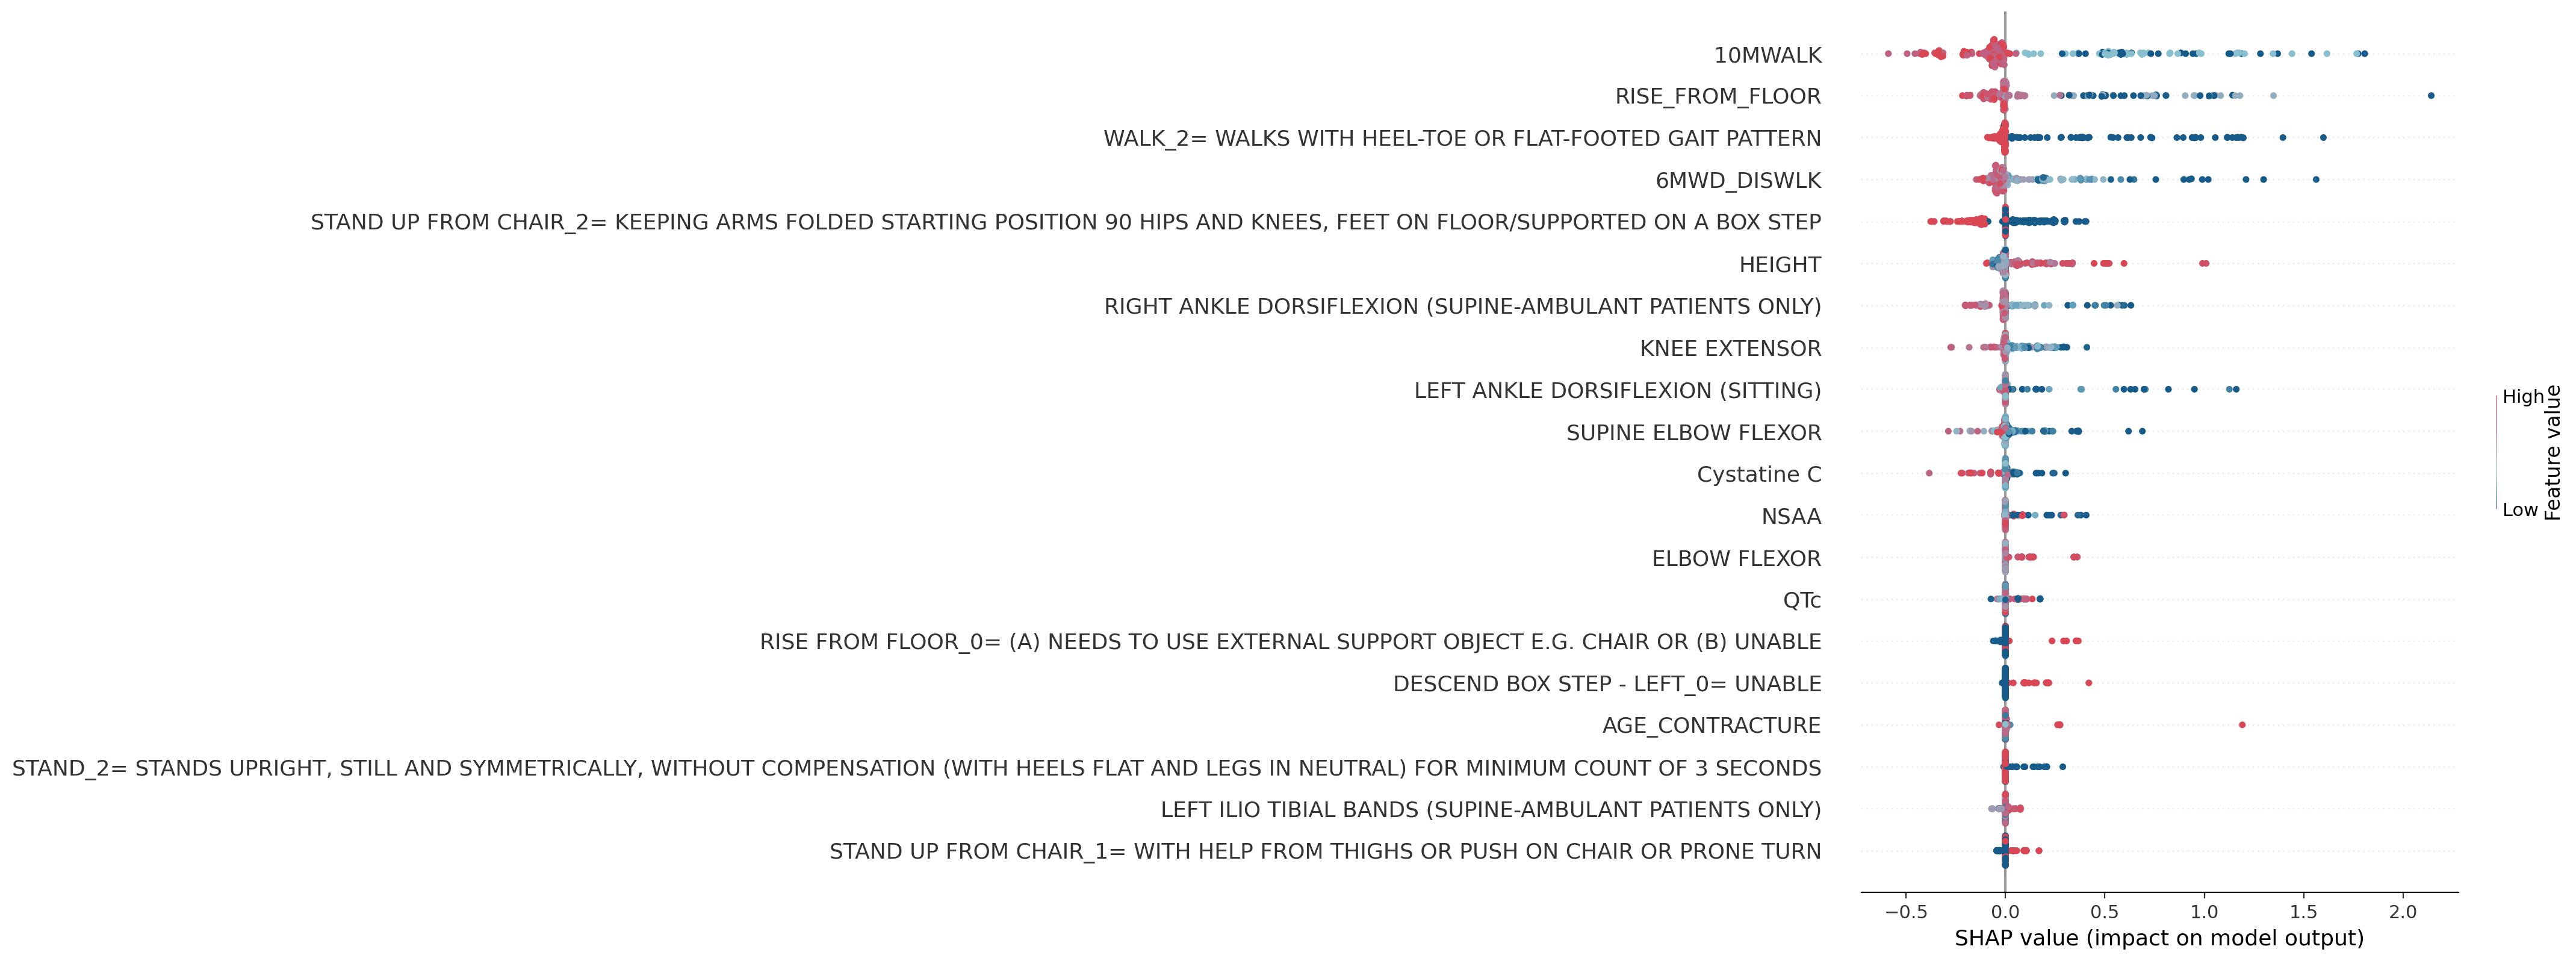

In [38]:
shap.summary_plot(gbsa_shap_values, gbsa_x_test, cmap=custom_cmap)

## C-GBSA

In [39]:
(c_gbsa_shap, 
 c_gbsa_shap_0, c_gbsa_shap_1, c_gbsa_shap_2, c_gbsa_shap_3, c_gbsa_shap_4, 
 c_gbsa_df, c_gbsa_summary_df) = shap_values_feature_importance('c-gbsa',5)

In [40]:
c_gbsa_summary_df

,fold_1,fold_2,fold_3,fold_4,fold_5,sum
Features,,,,,,
RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE,1,1,1,1,1,5
"WALK_1= PERSISTENT OR HABITUAL TOE WALKER, UNABLE TO HEEL-TOE CONSISTENTLY",1,1,1,1,1,5
"STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP",1,1,1,0,1,4
LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),1,0,1,1,1,4
RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY),1,1,0,1,1,4
DESCEND BOX STEP - LEFT_0= UNABLE,1,1,1,0,1,4
STAND UP FROM CHAIR_0= UNABLE,0,1,0,1,1,3
"TEARING PAPER_4= TEARS THE SHEET OF PAPER FOLDED IN 4, BEGINNING FROM THE FOLD EDGE",0,0,1,1,1,3
STAND ON ONE LEG - LEFT_0= UNABLE,0,0,0,1,1,2


In [41]:
c_gbsa = set(c_gbsa_summary_df.head(20).index.tolist())

In [42]:
c_gbsa

{'4SCD_SHOES_YES',
 'CLIMB BOX STEP - RIGHT_0= UNABLE',
 'DESCEND BOX STEP - LEFT_0= UNABLE',
 'LEFT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)',
 'MHINT_bin',
 'MUTATION_LOCATION_51',
 'MUTATION_TYPE_DELETION',
 'RACE_UNKNOWN',
 'RIGHT ANKLE DORSIFLEXION (SUPINE-AMBULANT PATIENTS ONLY)',
 'RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE',
 'RUN(10M)_0= WALK',
 'SHOULDER FLEXION TO SHOULDER HEIGHT_2= 200G',
 'STAND ON ONE LEG - LEFT_0= UNABLE',
 'STAND UP FROM CHAIR_0= UNABLE',
 'STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP',
 'STAND_1= STANDS STILL BUT WITH SOME DEGREE OF COMPENSATION (E.G. ON TOES OR WITH LEGS ABDUCTED OR WITH BOTTOM STUCK OUT) FOR MINIMUM COUNT OF 3 SECONDS',
 'STEROID_DOSE_37.5',
 'SUPINATION_3= PICKS UP THE LIGHT AND TURNS IT OVER COMPLETELY USING COMPENSATORY MOVEMENTS',
 'TEARING PAPER_4= TEARS THE SHEET OF PAPER FOLDED IN 4, BEGINNING FROM THE F

In [43]:
c_gbsa_shap_values, c_gbsa_x_test = concatenate('c-gbsa', 5)

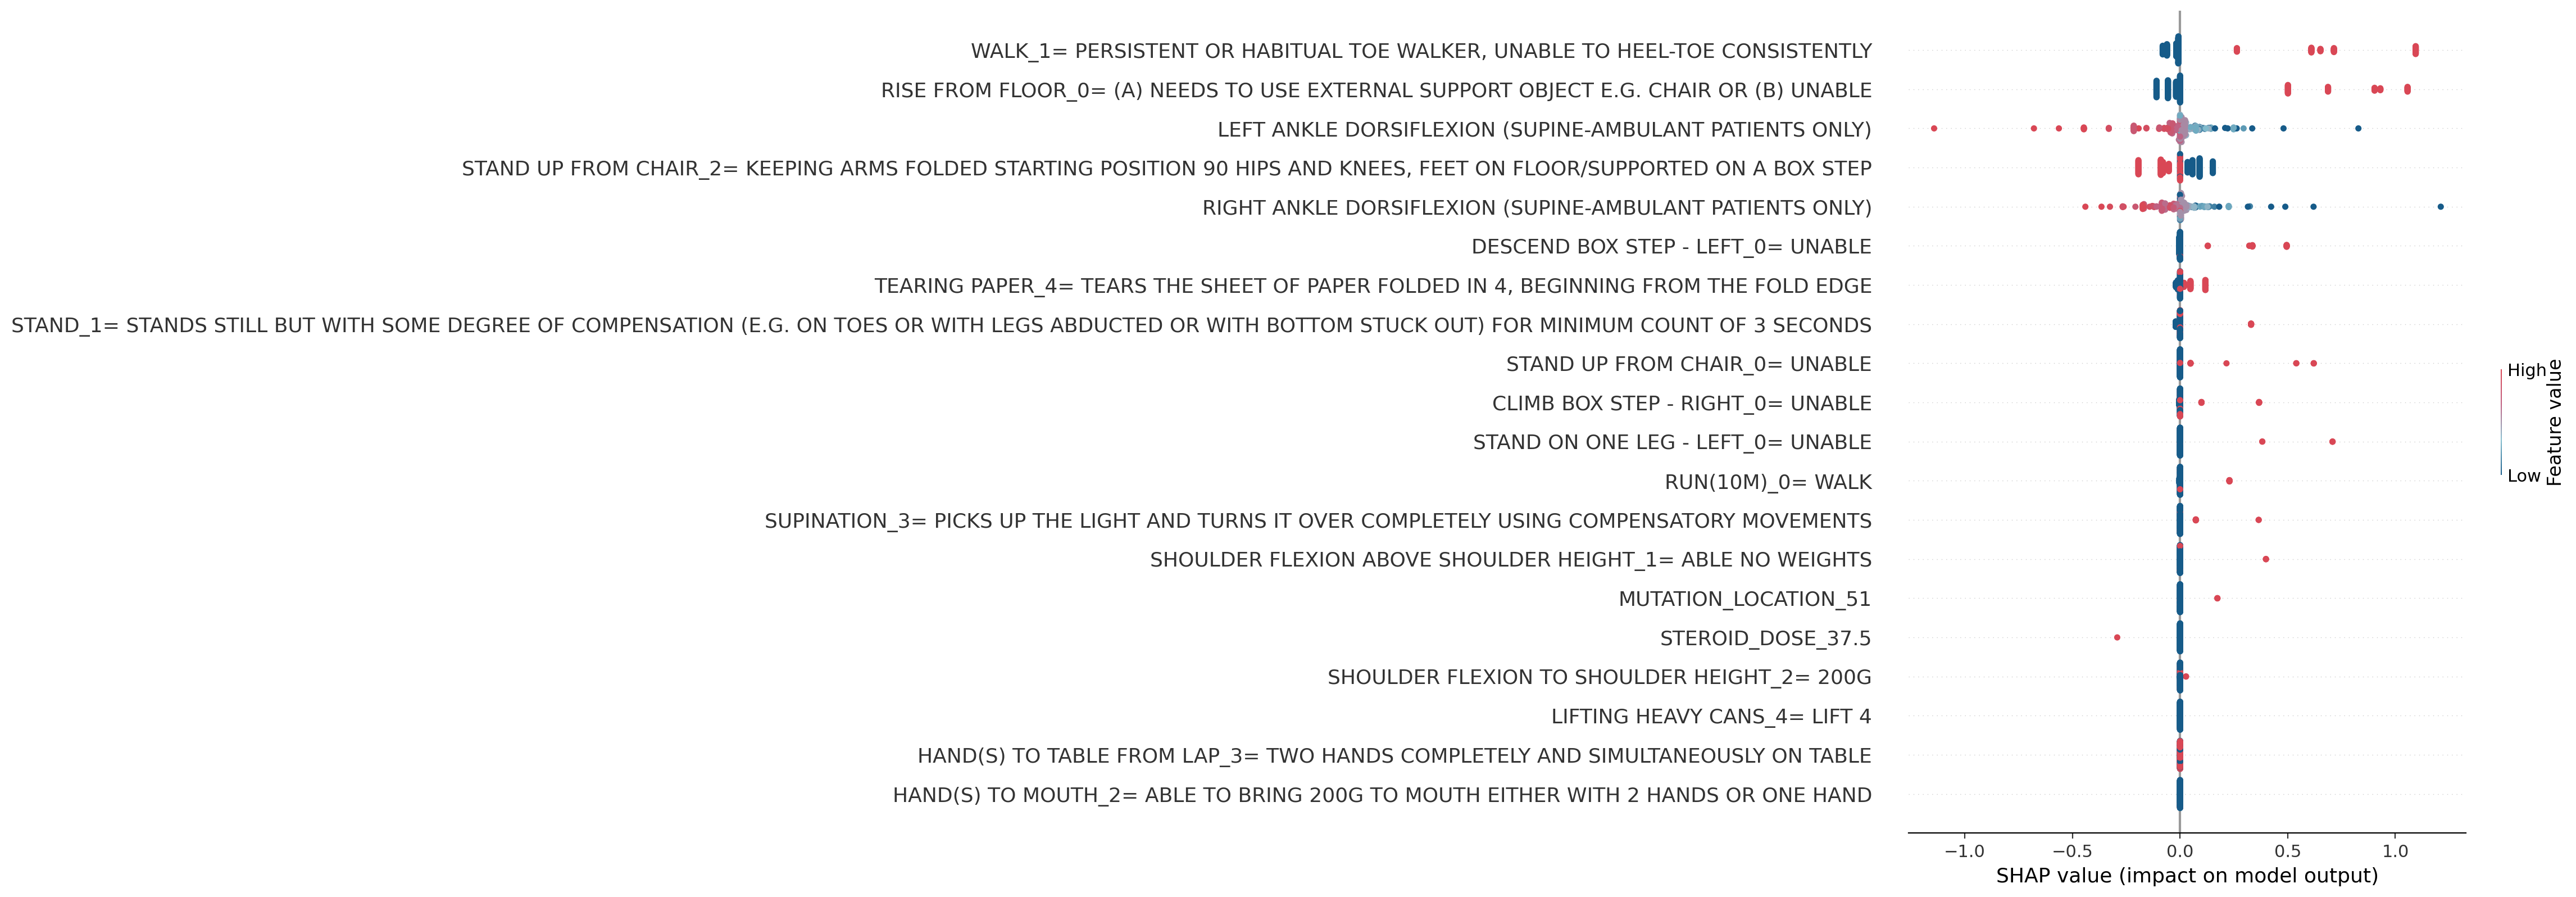

In [44]:
shap.summary_plot(c_gbsa_shap_values, c_gbsa_x_test, cmap=custom_cmap)

## Extra ST

In [45]:
(xst_shap, 
 xst_shap_0, xst_shap_1, xst_shap_2, xst_shap_3, xst_shap_4, 
 xst_df, xst_summary_df) = shap_values_feature_importance('xst',5)

In [46]:
xst_summary_df

,fold_1,fold_2,fold_3,fold_4,fold_5,sum
Features,,,,,,
WALK_2= WALKS WITH HEEL-TOE OR FLAT-FOOTED GAIT PATTERN,1,1,1,1,1,5
RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE,1,1,1,1,1,5
"STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP",1,1,1,1,1,5
"STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS",0,1,1,1,1,4
RISE FROM FLOOR_1= GOWERS EVIDENT,0,1,1,1,1,4
RISE_FROM_FLOOR,1,1,1,0,1,4
"WALK_1= PERSISTENT OR HABITUAL TOE WALKER, UNABLE TO HEEL-TOE CONSISTENTLY",1,1,1,0,1,4
STAND_1= STANDS STILL BUT WITH SOME DEGREE OF COMPENSATION (E.G. ON TOES OR WITH LEGS ABDUCTED OR WITH BOTTOM STUCK OUT) FOR MINIMUM COUNT OF 3 SECONDS,0,1,1,1,1,4
"TEARING PAPER_4= TEARS THE SHEET OF PAPER FOLDED IN 4, BEGINNING FROM THE FOLD EDGE",0,0,1,1,1,3


In [47]:
xst = set(xst_summary_df.head(20).index.tolist())

In [48]:
xst

{'10MWALK',
 '4SCA_SHOES_NO',
 'CLIMB BOX STEP - RIGHT_2= FACES STEP - NO SUPPORT NEEDED',
 'NSAA',
 'NURSYS_ABNORMAL',
 'RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE',
 'RISE FROM FLOOR_1= GOWERS EVIDENT',
 'RISE_FROM_FLOOR',
 'STAND UP FROM CHAIR_1= WITH HELP FROM THIGHS OR PUSH ON CHAIR OR PRONE TURN',
 'STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP',
 'STAND_1= STANDS STILL BUT WITH SOME DEGREE OF COMPENSATION (E.G. ON TOES OR WITH LEGS ABDUCTED OR WITH BOTTOM STUCK OUT) FOR MINIMUM COUNT OF 3 SECONDS',
 'STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS',
 'SUPINATION_4= PICKS UP THE LIGHT, AND TURNS THE HAND OVER COMPLETELY WITH NO COMPENSATORY MOVEMENTS',
 'TEARING PAPER_4= TEARS THE SHEET OF PAPER FOLDED IN 4, BEGINNING FROM THE FOLD EDGE',
 'WALK_1= PERSISTENT OR HABITUAL TOE WA

In [49]:
xst_shap_values, xst_x_test = concatenate('xst', 5)

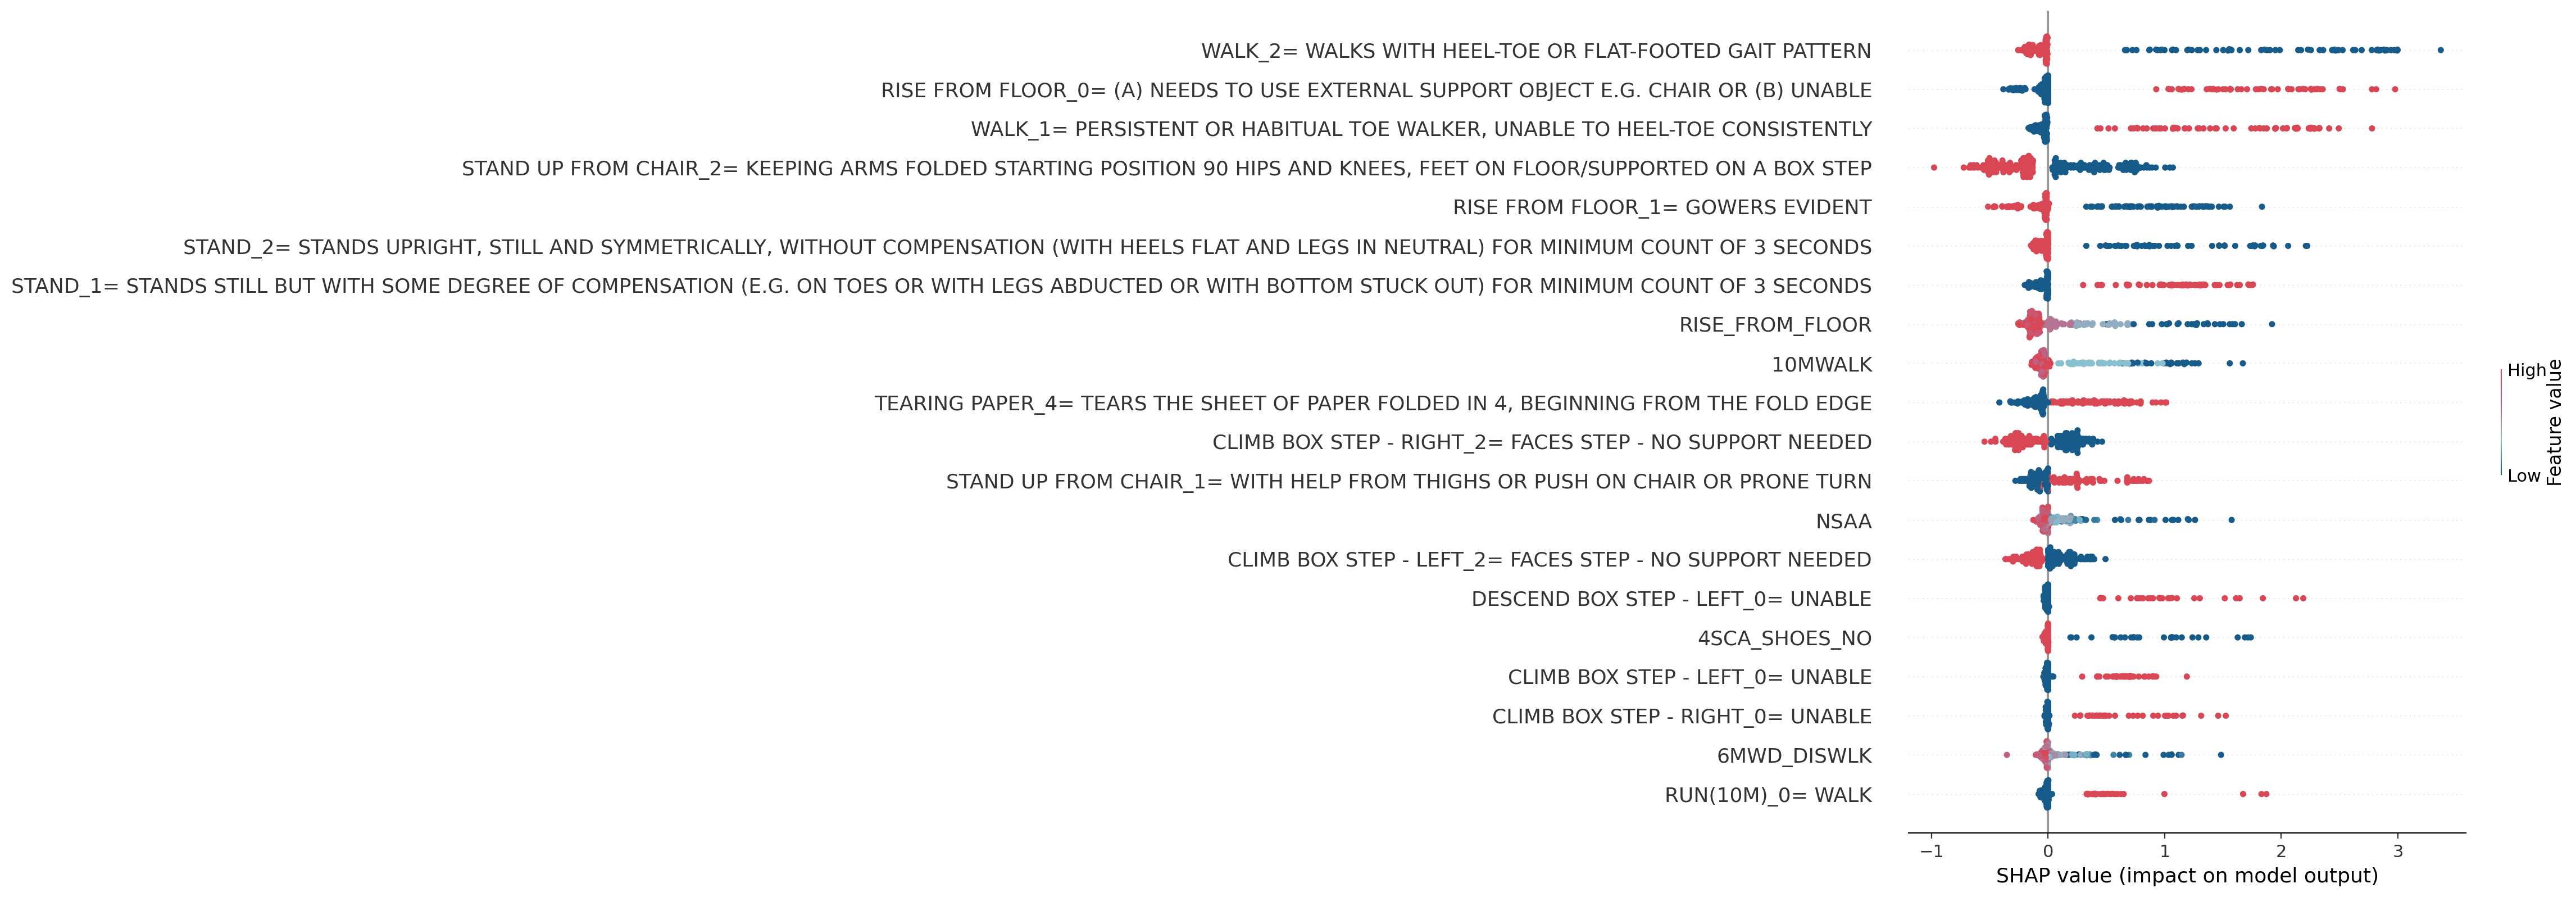

In [50]:
shap.summary_plot(xst_shap_values, xst_x_test, cmap=custom_cmap)

In [51]:
xst_x_test = xst_x_test.rename(columns={'WALK_2= WALKS WITH HEEL-TOE OR FLAT-FOOTED GAIT PATTERN':'WALK-2',
                                        'RISE FROM FLOOR_0= (A) NEEDS TO USE EXTERNAL SUPPORT OBJECT E.G. CHAIR OR (B) UNABLE': 'RISE FROM FLOOR-0', 
                                        'WALK_1= PERSISTENT OR HABITUAL TOE WALKER, UNABLE TO HEEL-TOE CONSISTENTLY':'WALK-1', 
                                        'RISE FROM FLOOR_1= GOWERS EVIDENT': 'RISE FROM FLOOR-1',
                                        'STAND UP FROM CHAIR_2= KEEPING ARMS FOLDED STARTING POSITION 90 HIPS AND KNEES, FEET ON FLOOR/SUPPORTED ON A BOX STEP': 'STAND UP FROM CHAIR-2', 
                                        'STAND_2= STANDS UPRIGHT, STILL AND SYMMETRICALLY, WITHOUT COMPENSATION (WITH HEELS FLAT AND LEGS IN NEUTRAL) FOR MINIMUM COUNT OF 3 SECONDS':'STAND-2', 
                                        'STAND_1= STANDS STILL BUT WITH SOME DEGREE OF COMPENSATION (E.G. ON TOES OR WITH LEGS ABDUCTED OR WITH BOTTOM STUCK OUT) FOR MINIMUM COUNT OF 3 SECONDS': 'STAND-1', 
                                        'RISE_FROM_FLOOR': 'RISE FROM FLOOR', 
                                        'TEARING PAPER_4= TEARS THE SHEET OF PAPER FOLDED IN 4, BEGINNING FROM THE FOLD EDGE': 'TEARING PAPER-4',
                                        'CLIMB BOX STEP - LEFT_2= FACES STEP - NO SUPPORT NEEDED': 'CLIMB BOX STEP-L-2',
                                        'CLIMB BOX STEP - RIGHT_2= FACES STEP - NO SUPPORT NEEDED': 'CLIMB BOX STEP-R-2',
                                        '4SCD_SHOES_NO': '4SCD-SHOES-NO',
                                        'CLIMB BOX STEP - RIGHT_0= UNABLE': 'CLIMB BOX STEP-R-0',
                                        'STAND UP FROM CHAIR_1= WITH HELP FROM THIGHS OR PUSH ON CHAIR OR PRONE TURN': 'STAND UP FROM CHAIR-1',
                                        '6MWD_DISWLK': '6MWD-DISWLK', 
                                        'RUN(10M)_0= WALK': 'RUN10M-0',         
                                        'JUMP_2= BOTH FEET AT THE SAME TIME, CLEAR THE GROUND SIMULTANEOUSLY': 'JUMP 2',
                                        '4SCA_SHOES_NO': '4SCA-SHOES-NO',                                         
                                        'DESCEND BOX STEP - LEFT_0= UNABLE': 'DESCEND BOX STEP-L-0'
                                       })

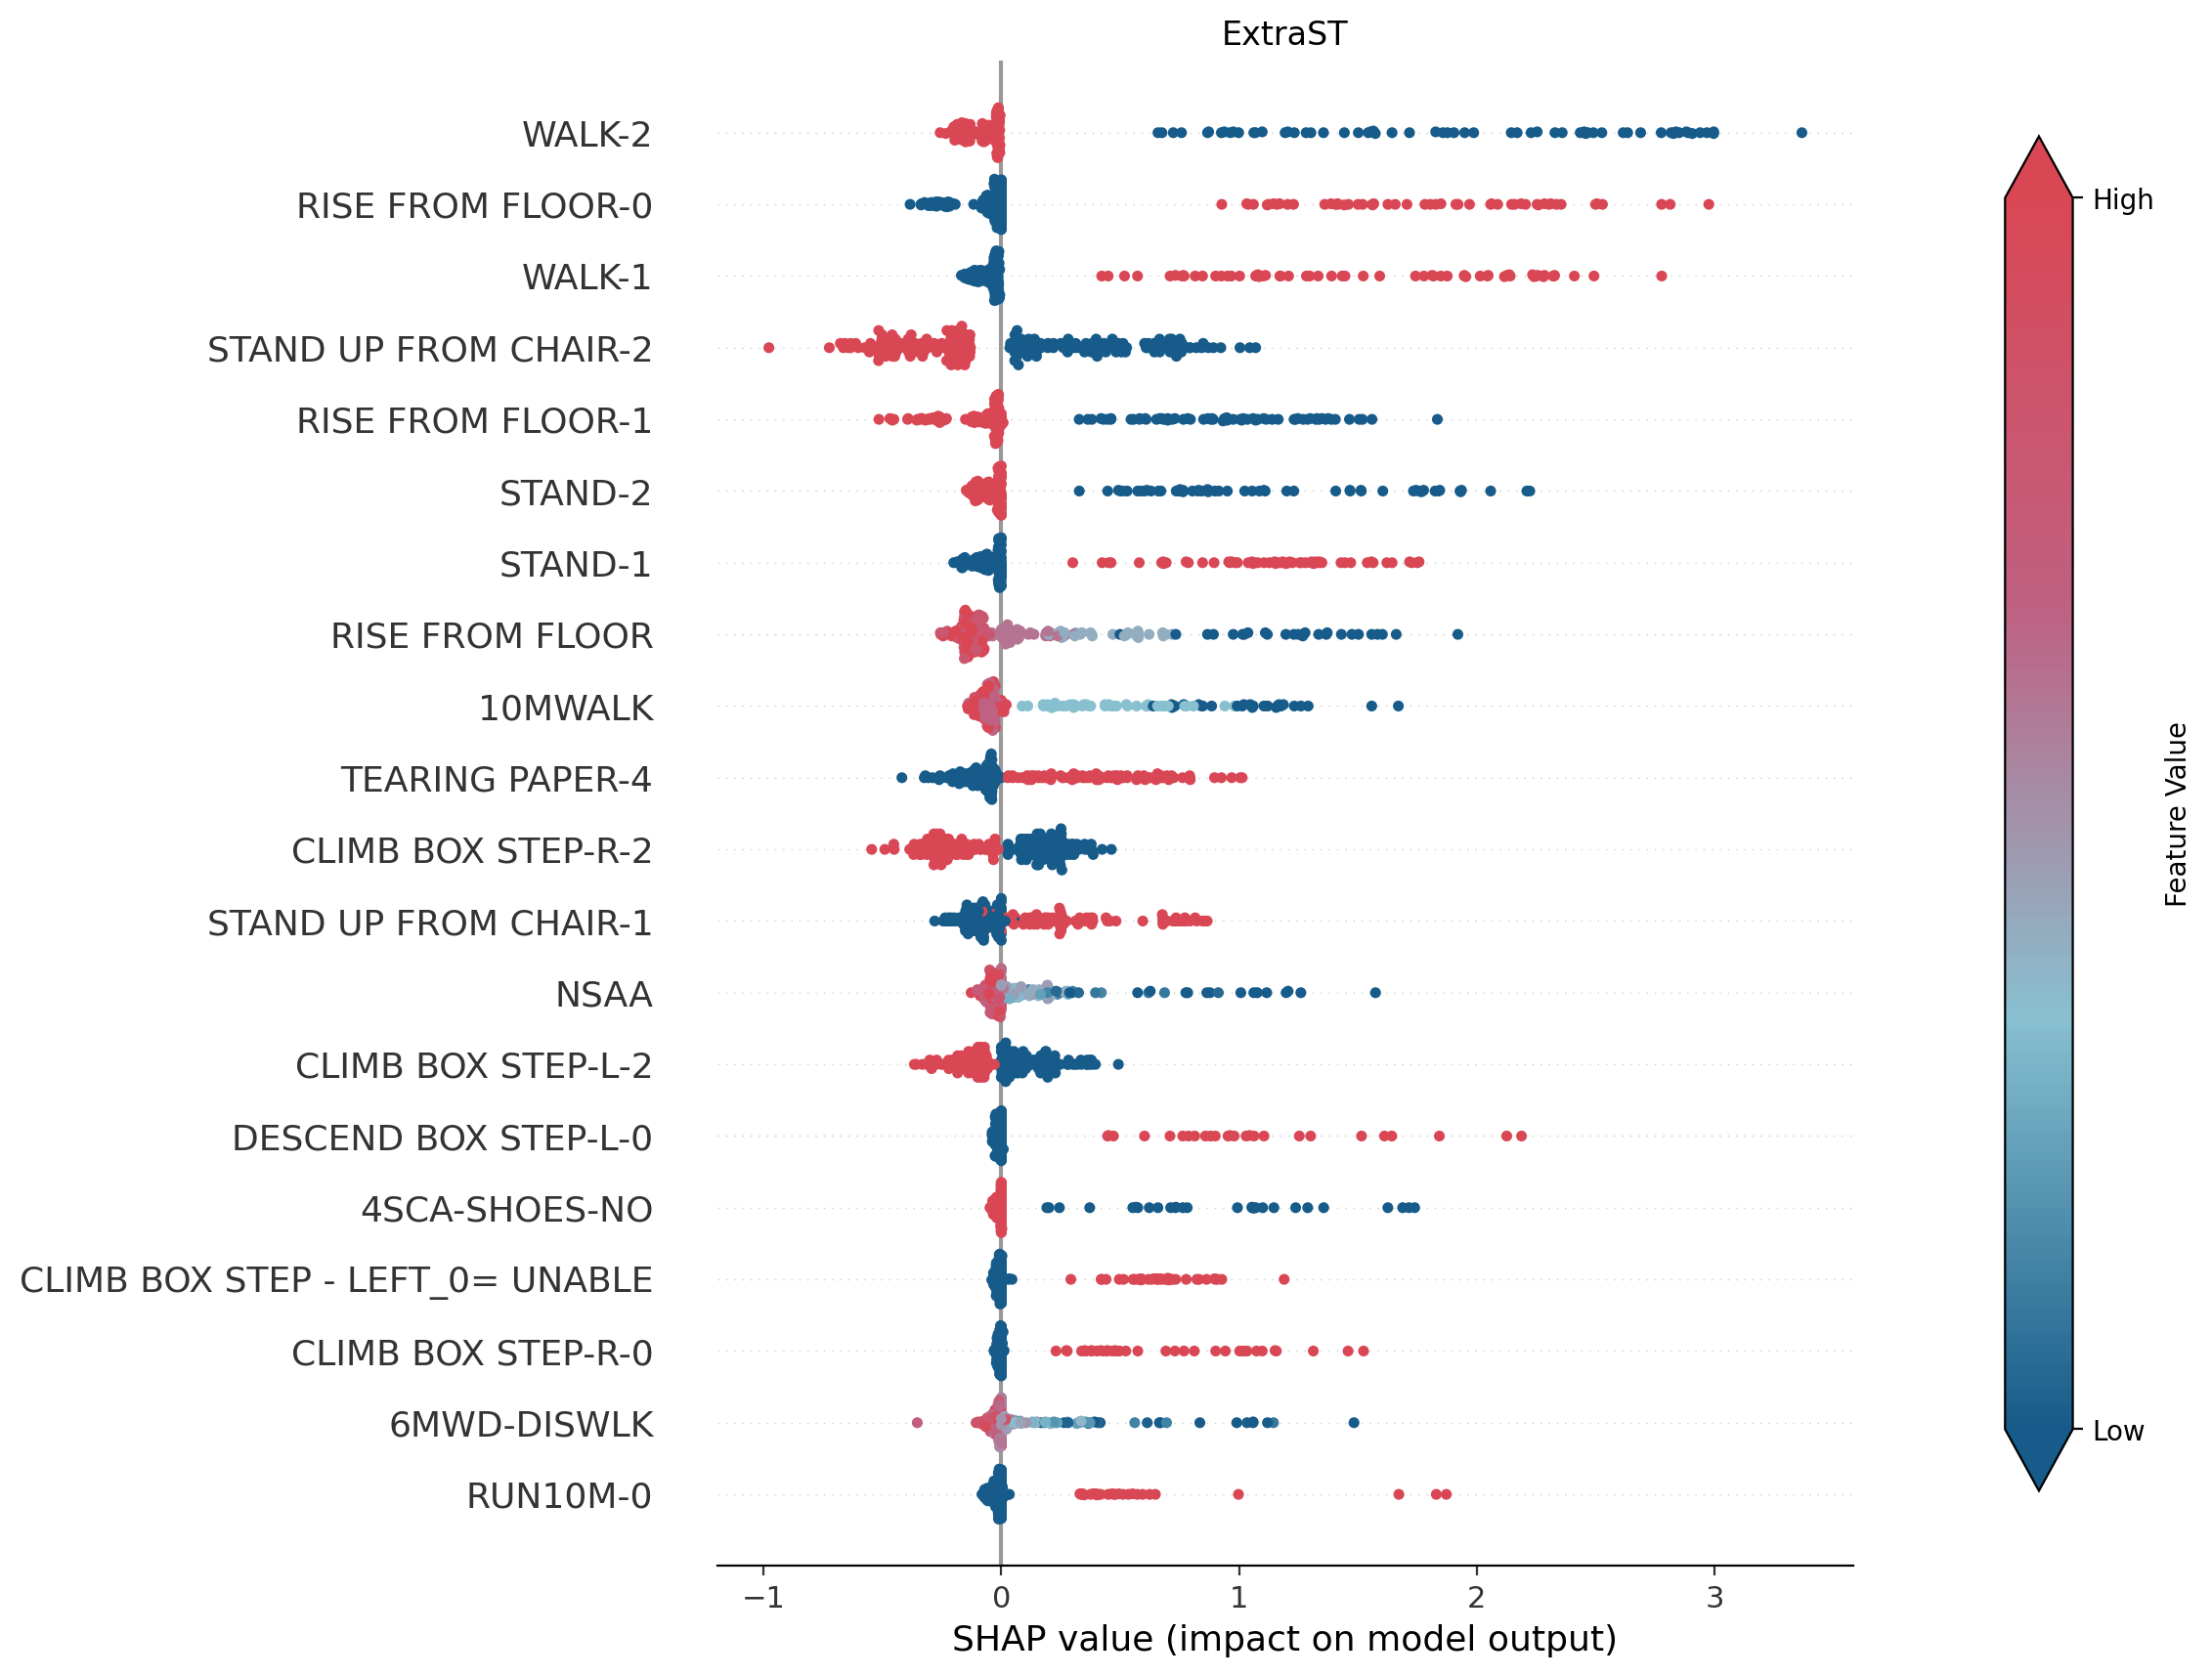

In [52]:
fig = plt.figure()
shap.summary_plot(xst_shap_values, xst_x_test, show=False, cmap=plt.cm.get_cmap(custom_cmap), color_bar=False)
plt.gcf().set_size_inches(10,10)
plt.title('ExtraST')
cbar = plt.colorbar(label='Feature Value',  
                    extend='both',
                    pad=0.1, 
                    shrink=0.9)
cbar.set_ticks([0,1])
cbar.set_ticklabels(["Low","High"])
plt.show()